## 1.    Pacotes Python Usados no Projeto

In [159]:
# Instalação dos pacotes (execute apenas se faltar algum)
# %pip install -q -U watermark
# %pip install scikit-learn
# %pip install statsmodels 
# %pip install openpyxl

In [160]:
# Manipulação de dados
import numpy as np
import pandas as pd

# Visualização
import matplotlib.pyplot as plt
import seaborn as sns

# Modelagem
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_validate, cross_val_predict)
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             roc_auc_score, precision_score, recall_score, f1_score,
                             precision_recall_curve, ConfusionMatrixDisplay,
                             RocCurveDisplay)

# Estatística (p-valores e VIF)
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Ignorar avisos para manter a saída do notebook limpa
import warnings
warnings.filterwarnings('ignore')

In [161]:
# Reproduzibilidade
%load_ext watermark
%watermark -a "Lucas Rodrigues Cazane" -d -t -v -p numpy,pandas,matplotlib,seaborn,sklearn,statsmodels

The watermark extension is already loaded. To reload it, use:
  %reload_ext watermark
Author: Lucas Rodrigues Cazane

Date/Time: 2026-10-28 09:59:54

Python implementation: CPython
Python version       : 3.14.7
IPython version      : 9.16.1

numpy      : 2.5.2
pandas     : 3.0.5
matplotlib : 3.11.1
seaborn    : 0.13.2
sklearn    : 1.9.1
statsmodels: 0.15.0



## 2.   Carregando os Dados


In [162]:
# Carregando o dataset
df_inicial = pd.read_csv('loan_data.csv')

In [163]:
# Numero de linhas e colunas do dataset
df_inicial.shape

(45000, 14)

In [164]:
df_inicial

,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status
0,22.0,female,Master,71948.0,0,RENT,35000.0,PERSONAL,16.02,0.49,3.0,561,No,1
1,21.0,female,High School,12282.0,0,OWN,1000.0,EDUCATION,11.14,0.08,2.0,504,Yes,0
2,25.0,female,High School,12438.0,3,MORTGAGE,5500.0,MEDICAL,12.87,0.44,3.0,635,No,1
3,23.0,female,Bachelor,79753.0,0,RENT,35000.0,MEDICAL,15.23,0.44,2.0,675,No,1
4,24.0,male,Master,66135.0,1,RENT,35000.0,MEDICAL,14.27,0.53,4.0,586,No,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44995,27.0,male,Associate,47971.0,6,RENT,15000.0,MEDICAL,15.66,0.31,3.0,645,No,1
44996,37.0,female,Associate,65800.0,17,RENT,9000.0,HOMEIMPROVEMENT,14.07,0.14,11.0,621,No,1
44997,33.0,male,Associate,56942.0,7,RENT,2771.0,DEBTCONSOLIDATION,10.02,0.05,10.0,668,No,1
44998,29.0,male,Bachelor,33164.0,4,RENT,12000.0,EDUCATION,13.23,0.36,6.0,604,No,1


## 3.   Análise Exploratória

In [165]:
# Carregando a planilha de metadados
metadados = pd.read_excel('Metadados.xlsx')

In [166]:
metadados

,Coluna,Descrição
0,person_age,Idade da pessoa
1,person_gender,Gênero da pessoa
2,person_education,Nível de escolaridade mais elevado
3,person_income,Renda anual
4,person_emp_exp,Anos de experiência profissional
5,person_home_ownership,Situação de propriedade do imóvel (ex.: alugad...
6,loan_amnt,Valor do empréstimo solicitado
7,loan_intent,Finalidade do empréstimo
8,loan_int_rate,Taxa de juros do empréstimo
9,loan_percent_income,Valor do empréstimo como percentagem do rendim...


In [167]:
# Esta célula renomeia as colunas para português, na mesma ordem do arquivo original.
df_inicial.columns = [
    "Idade", "Sexo", "Escolaridade",  "Renda anual", "Anos de Experiência Profissional", "Situação de Propriedade", "Valor Emprestimo Solicitado", 
    "Finalidade do Emprestimo", "Tx de Juros Emprestimo A.A.", "Percentual do Emprestimo pela Renda Anual",
    "Histórico de Crédito(em Anos)", "Score Pessoa", "Indicador de inadimplência de Empréstimos Anteriores", "Status da Aprovação do Empréstimo", 
]

In [168]:
df_inicial

,Idade,Sexo,Escolaridade,Renda anual,Anos de Experiência Profissional,Situação de Propriedade,Valor Emprestimo Solicitado,Finalidade do Emprestimo,Tx de Juros Emprestimo A.A.,Percentual do Emprestimo pela Renda Anual,Histórico de Crédito(em Anos),Score Pessoa,Indicador de inadimplência de Empréstimos Anteriores,Status da Aprovação do Empréstimo
0,22.0,female,Master,71948.0,0,RENT,35000.0,PERSONAL,16.02,0.49,3.0,561,No,1
1,21.0,female,High School,12282.0,0,OWN,1000.0,EDUCATION,11.14,0.08,2.0,504,Yes,0
2,25.0,female,High School,12438.0,3,MORTGAGE,5500.0,MEDICAL,12.87,0.44,3.0,635,No,1
3,23.0,female,Bachelor,79753.0,0,RENT,35000.0,MEDICAL,15.23,0.44,2.0,675,No,1
4,24.0,male,Master,66135.0,1,RENT,35000.0,MEDICAL,14.27,0.53,4.0,586,No,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44995,27.0,male,Associate,47971.0,6,RENT,15000.0,MEDICAL,15.66,0.31,3.0,645,No,1
44996,37.0,female,Associate,65800.0,17,RENT,9000.0,HOMEIMPROVEMENT,14.07,0.14,11.0,621,No,1
44997,33.0,male,Associate,56942.0,7,RENT,2771.0,DEBTCONSOLIDATION,10.02,0.05,10.0,668,No,1
44998,29.0,male,Bachelor,33164.0,4,RENT,12000.0,EDUCATION,13.23,0.36,6.0,604,No,1


In [169]:
df_inicial.info()

<class 'pandas.DataFrame'>
RangeIndex: 45000 entries, 0 to 44999
Data columns (total 14 columns):
 #   Column                                                Non-Null Count  Dtype  
---  ------                                                --------------  -----  
 0   Idade                                                 45000 non-null  float64
 1   Sexo                                                  45000 non-null  str    
 2   Escolaridade                                          45000 non-null  str    
 3   Renda anual                                           45000 non-null  float64
 4   Anos de Experiência Profissional                      45000 non-null  int64  
 5   Situação de Propriedade                               45000 non-null  str    
 6   Valor Emprestimo Solicitado                           45000 non-null  float64
 7   Finalidade do Emprestimo                              45000 non-null  str    
 8   Tx de Juros Emprestimo A.A.                           45000 non-nul

-  Verificando as variáveis:

1- O df não possui dados nulos.

2- Analisandos os Dtypes das colunas não idendifiquei ajustes necessários nesse momento.


In [170]:
# Verificando se existem registros duplicados no dataset
df_inicial[df_inicial.duplicated()]

,Idade,Sexo,Escolaridade,Renda anual,Anos de Experiência Profissional,Situação de Propriedade,Valor Emprestimo Solicitado,Finalidade do Emprestimo,Tx de Juros Emprestimo A.A.,Percentual do Emprestimo pela Renda Anual,Histórico de Crédito(em Anos),Score Pessoa,Indicador de inadimplência de Empréstimos Anteriores,Status da Aprovação do Empréstimo


In [171]:
# Estatísticas descritivas variavés não numericas
df_inicial[['Sexo', 'Escolaridade', 'Situação de Propriedade', 'Finalidade do Emprestimo', 'Indicador de inadimplência de Empréstimos Anteriores']].describe()

,Sexo,Escolaridade,Situação de Propriedade,Finalidade do Emprestimo,Indicador de inadimplência de Empréstimos Anteriores
count,45000,45000,45000,45000,45000
unique,2,5,4,6,2
top,male,Bachelor,RENT,EDUCATION,Yes
freq,24841,13399,23443,9153,22858


In [172]:
# Estudo dos valores únicos das variáeis não numericas
valores_unicos_sexo = sorted(df_inicial["Sexo"].unique())
print(f'Valores únicos para Sexo: {valores_unicos_sexo}')
valores_unicos_escolaridade = sorted(df_inicial["Escolaridade"].unique())
print(f'Valores únicos para Escolaridade: {valores_unicos_escolaridade}')
valores_unicos_situacao_propriedade = sorted(df_inicial["Situação de Propriedade"].unique())
print(f'Valores únicos para Situação de Propriedade: {valores_unicos_situacao_propriedade}')
valores_unicos_finalidade_emprestimo = sorted(df_inicial["Finalidade do Emprestimo"].unique())
print(f'Valores únicos para Finalidade do Emprestimo: {valores_unicos_finalidade_emprestimo}')
valores_unicos_indicador_inadimplencia = sorted(df_inicial["Indicador de inadimplência de Empréstimos Anteriores"].unique())
print(f'Valores únicos para Indicador de inadimplência de Empréstimos Anteriores: {valores_unicos_indicador_inadimplencia}')


Valores únicos para Sexo: ['female', 'male']
Valores únicos para Escolaridade: ['Associate', 'Bachelor', 'Doctorate', 'High School', 'Master']
Valores únicos para Situação de Propriedade: ['MORTGAGE', 'OTHER', 'OWN', 'RENT']
Valores únicos para Finalidade do Emprestimo: ['DEBTCONSOLIDATION', 'EDUCATION', 'HOMEIMPROVEMENT', 'MEDICAL', 'PERSONAL', 'VENTURE']
Valores únicos para Indicador de inadimplência de Empréstimos Anteriores: ['No', 'Yes']


In [173]:
df_inicial

,Idade,Sexo,Escolaridade,Renda anual,Anos de Experiência Profissional,Situação de Propriedade,Valor Emprestimo Solicitado,Finalidade do Emprestimo,Tx de Juros Emprestimo A.A.,Percentual do Emprestimo pela Renda Anual,Histórico de Crédito(em Anos),Score Pessoa,Indicador de inadimplência de Empréstimos Anteriores,Status da Aprovação do Empréstimo
0,22.0,female,Master,71948.0,0,RENT,35000.0,PERSONAL,16.02,0.49,3.0,561,No,1
1,21.0,female,High School,12282.0,0,OWN,1000.0,EDUCATION,11.14,0.08,2.0,504,Yes,0
2,25.0,female,High School,12438.0,3,MORTGAGE,5500.0,MEDICAL,12.87,0.44,3.0,635,No,1
3,23.0,female,Bachelor,79753.0,0,RENT,35000.0,MEDICAL,15.23,0.44,2.0,675,No,1
4,24.0,male,Master,66135.0,1,RENT,35000.0,MEDICAL,14.27,0.53,4.0,586,No,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44995,27.0,male,Associate,47971.0,6,RENT,15000.0,MEDICAL,15.66,0.31,3.0,645,No,1
44996,37.0,female,Associate,65800.0,17,RENT,9000.0,HOMEIMPROVEMENT,14.07,0.14,11.0,621,No,1
44997,33.0,male,Associate,56942.0,7,RENT,2771.0,DEBTCONSOLIDATION,10.02,0.05,10.0,668,No,1
44998,29.0,male,Bachelor,33164.0,4,RENT,12000.0,EDUCATION,13.23,0.36,6.0,604,No,1


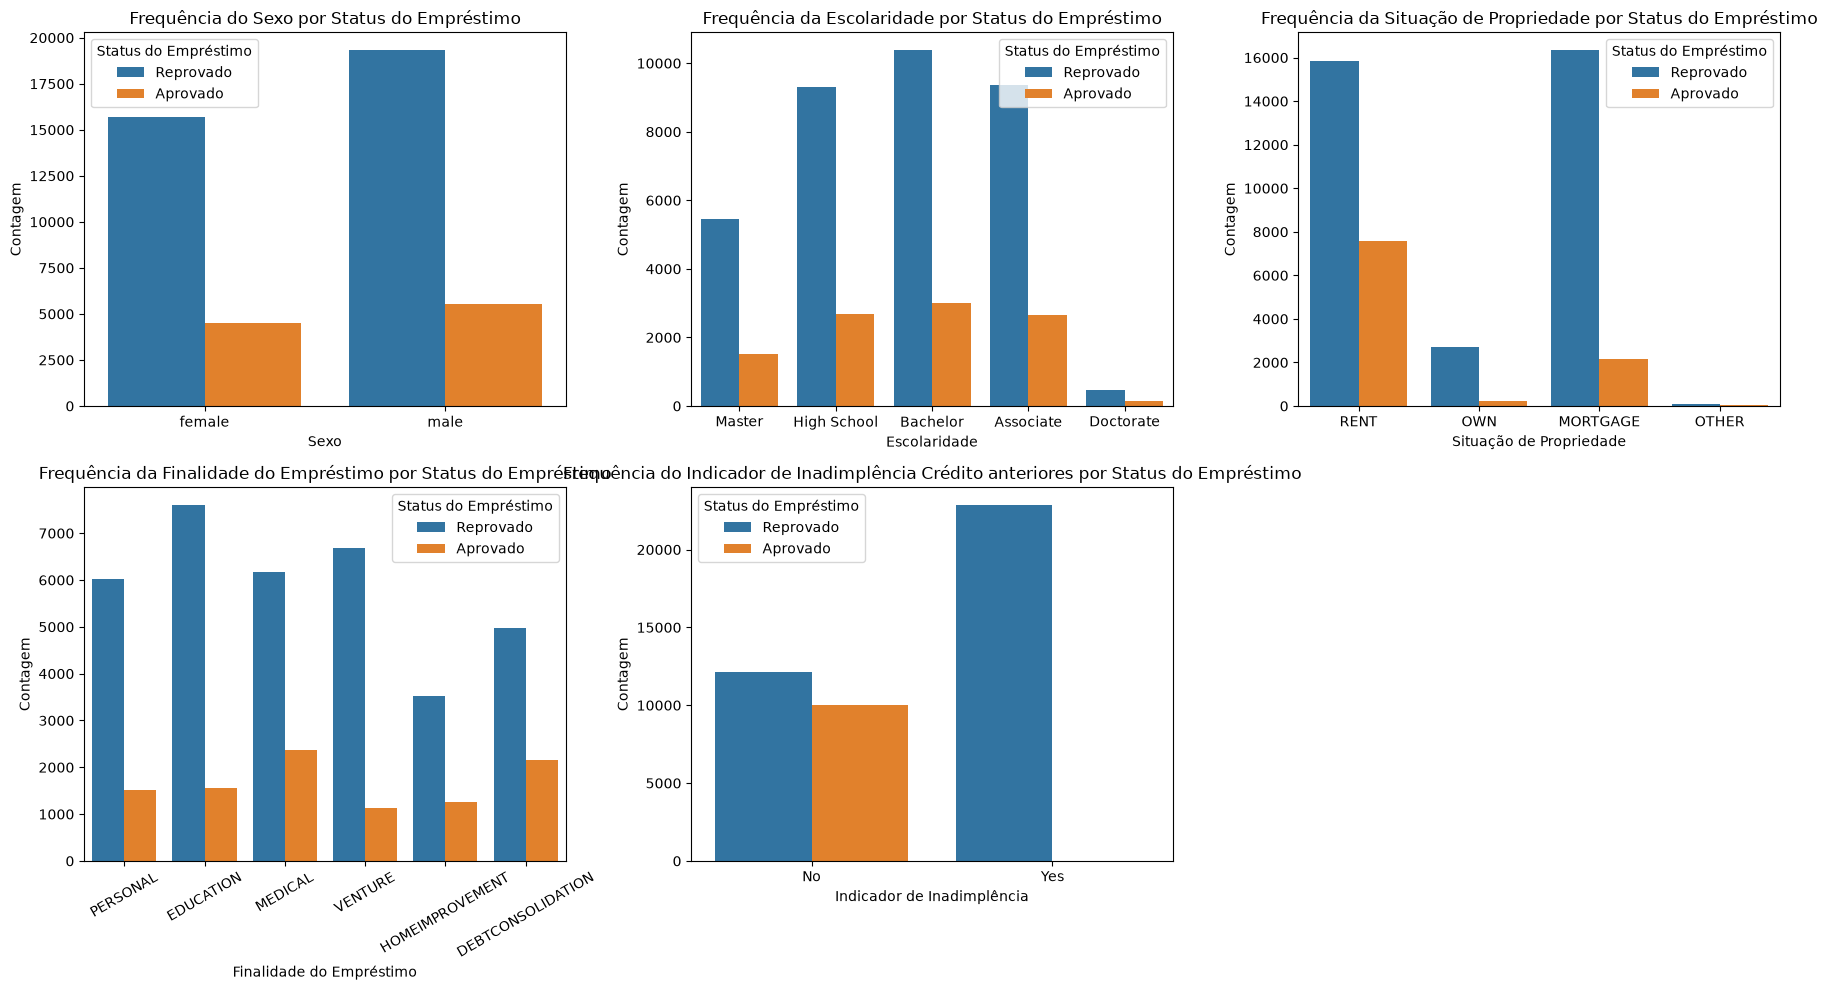

In [174]:
# Comparando variáveis não numéricas por status do empréstimo
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()
status_emprestimo = df_inicial['Status da Aprovação do Empréstimo'].map({0: 'Reprovado', 1: 'Aprovado'})

# Gráfico por Sexo (person_gender):
sns.countplot(data=df_inicial, x='Sexo', hue=status_emprestimo,
              hue_order=['Reprovado', 'Aprovado'], ax=axes[0])
axes[0].set_title('Frequência do Sexo por Status do Empréstimo')
axes[0].set_xlabel('Sexo')
axes[0].set_ylabel('Contagem')
axes[0].legend(title='Status do Empréstimo')

# Gráfico por nível de escolaridade (person_education):
sns.countplot(data=df_inicial, x='Escolaridade', hue=status_emprestimo,
              hue_order=['Reprovado', 'Aprovado'], ax=axes[1])
axes[1].set_title('Frequência da Escolaridade por Status do Empréstimo')
axes[1].set_xlabel('Escolaridade')
axes[1].set_ylabel('Contagem')
axes[1].legend(title='Status do Empréstimo')

# Gráficos por situação de propriedade (person_home_ownership):
sns.countplot(data=df_inicial, x='Situação de Propriedade', hue=status_emprestimo,
              hue_order=['Reprovado', 'Aprovado'], ax=axes[2])
axes[2].set_title('Frequência da Situação de Propriedade por Status do Empréstimo')
axes[2].set_xlabel('Situação de Propriedade')
axes[2].set_ylabel('Contagem')
axes[2].legend(title='Status do Empréstimo')

# Gráficos por intenção de empréstimo (loan_intent):
sns.countplot(data=df_inicial, x='Finalidade do Emprestimo', hue=status_emprestimo,
              hue_order=['Reprovado', 'Aprovado'], ax=axes[3])
axes[3].set_title('Frequência da Finalidade do Empréstimo por Status do Empréstimo')
axes[3].set_xlabel('Finalidade do Empréstimo')
axes[3].set_ylabel('Contagem')
axes[3].tick_params(axis='x', labelrotation=30)
axes[3].legend(title='Status do Empréstimo')

# Gráficos por indicador de inadimplência de empréstimos anteriores (previous_loan_defaults_on_file):
sns.countplot(data=df_inicial, x='Indicador de inadimplência de Empréstimos Anteriores', hue=status_emprestimo,
              hue_order=['Reprovado', 'Aprovado'], ax=axes[4])
axes[4].set_title('Frequência do Indicador de Inadimplência Crédito anteriores por Status do Empréstimo')
axes[4].set_xlabel('Indicador de Inadimplência')
axes[4].set_ylabel('Contagem')
axes[4].legend(title='Status do Empréstimo')

axes[5].set_visible(False)
plt.tight_layout()
plt.show()

- Algumas considerações sobre os gráficos:  
    - Por questões éticas não iremos utilizar a coluna Sexo como variável do modelo.   
    - Iremos testar as outras variáveis em nosso modelo para avaliarmos quais apresentam maior relação com o Status do Emprestimo.   
    - Todas os clientes que tiveram Indicador de Inadimplencia de emprestimos anteriores tiveram seus emprestimos Reprovados.

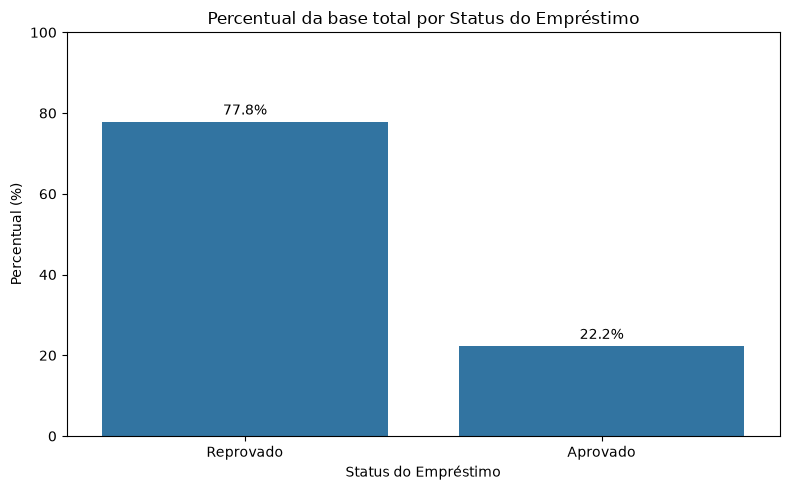

In [175]:
# Percentual de empréstimos aprovados e reprovados
status_emprestimo = df_inicial['Status da Aprovação do Empréstimo'].map({0: 'Reprovado', 1: 'Aprovado'})

fig, ax = plt.subplots(figsize=(8, 5))
sns.countplot(
    x=status_emprestimo,
    order=['Reprovado', 'Aprovado'],
    stat='percent',
    ax=ax
)

ax.set_title('Percentual da base total por Status do Empréstimo')
ax.set_xlabel('Status do Empréstimo')
ax.set_ylabel('Percentual (%)')
ax.set_ylim(0, 100)
ax.bar_label(ax.containers[0], fmt='%.1f%%', padding=3)

plt.tight_layout()
plt.show()

-   Baseline (Modelo “Burro”)

    -   A variável alvo Status do Emprestimo é desbalanceada: 77,8% dos empréstimos foram reprovados (classe 0) e 22,2% aprovados (classe 1). Um modelo “burro” que sempre prevê a classe majoritária (reprovado) alcançaria, portanto, 77,8% de acurácia sem aprender nada.

    -   Esse valor é o piso de desempenho: para ser útil, a regressão logística precisa superá-lo (Por uma questão metodológica iremos fazer esse levantamento para a base de teste. Onde os valores devem ser muito próximos da base total). Como a acurácia pode enganar em bases desbalanceadas, a avaliação também incluirá precision, recall, F1-score, matriz de confusão e ROC-AUC, já que o modelo burro tem recall zero para a classe “aprovado”.

In [176]:
# Estatísticas descritivas da variáveis numéricas
df_inicial.describe().round(2)

,Idade,Renda anual,Anos de Experiência Profissional,Valor Emprestimo Solicitado,Tx de Juros Emprestimo A.A.,Percentual do Emprestimo pela Renda Anual,Histórico de Crédito(em Anos),Score Pessoa,Status da Aprovação do Empréstimo
count,45000.00,45000.00,45000.00,45000.00,45000.00,45000.00,45000.00,45000.00,45000.00
mean,27.76,80319.05,5.41,9583.16,11.01,0.14,5.87,632.61,0.22
std,6.05,80422.50,6.06,6314.89,2.98,0.09,3.88,50.44,0.42
min,20.00,8000.00,0.00,500.00,5.42,0.00,2.00,390.00,0.00
25%,24.00,47204.00,1.00,5000.00,8.59,0.07,3.00,601.00,0.00
50%,26.00,67048.00,4.00,8000.00,11.01,0.12,4.00,640.00,0.00
75%,30.00,95789.25,8.00,12237.25,12.99,0.19,8.00,670.00,0.00
max,144.00,7200766.00,125.00,35000.00,20.00,0.66,30.00,850.00,1.00


- Idade:

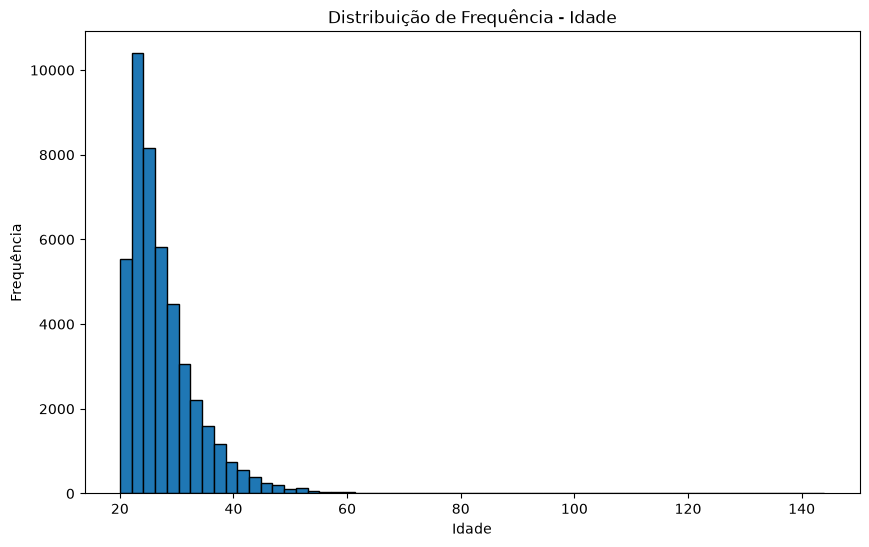

In [177]:
# Gerando um grafico dedistribuição de frequencia da variavel Idade por apresentar valores extremos
plt.figure(figsize=(10, 6))
plt.hist(df_inicial['Idade'], bins=60, edgecolor='black')
plt.title('Distribuição de Frequência - Idade')
plt.xlabel('Idade')
plt.ylabel('Frequência')
plt.show()  

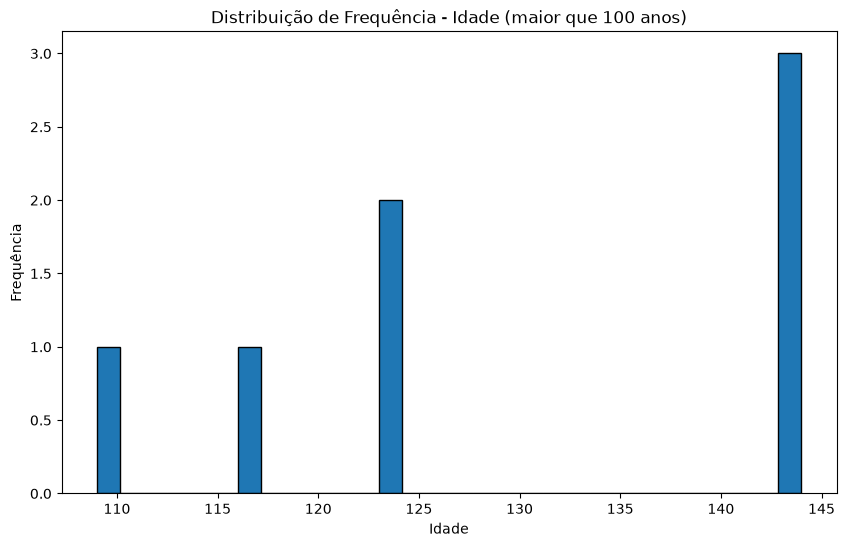

In [178]:
# Gerando um grafico dedistribuição de frequencia da variavel Idade para idade maior que 100 anos
plt.figure(figsize=(10, 6))
plt.hist(df_inicial[df_inicial['Idade'] > 100]['Idade'], bins=30, edgecolor='black')
plt.title('Distribuição de Frequência - Idade (maior que 100 anos)')
plt.xlabel('Idade')
plt.ylabel('Frequência')
plt.show()

In [179]:
# Quantos registros são suspeitos de erro?
df_inicial[df_inicial['Idade'] > 100].shape[0]


7

In [180]:
# Percentual de registros suspeitos de erro em relação ao total de registros
percentual_suspeitos = (df_inicial[df_inicial['Idade'] > 100].shape[0] / df_inicial.shape[0]) * 100
print(f'Percentual de registros suspeitos de erro: {percentual_suspeitos:.2f}%')

Percentual de registros suspeitos de erro: 0.02%


- Utilizaremos como parámetro máximo a idade de 100 anos e por isso 7 registros que superam essa marca iremos tratar como erro de digitação.

In [181]:
# Excluindo registros com idade maior que 100 anos.
df_inicial = df_inicial[df_inicial['Idade'] <= 100].copy()

In [182]:
# Estatísticas descritivas
df_inicial.describe().round(2)

,Idade,Renda anual,Anos de Experiência Profissional,Valor Emprestimo Solicitado,Tx de Juros Emprestimo A.A.,Percentual do Emprestimo pela Renda Anual,Histórico de Crédito(em Anos),Score Pessoa,Status da Aprovação do Empréstimo
count,44993.00,44993.00,44993.00,44993.00,44993.00,44993.00,44993.00,44993.00,44993.00
mean,27.75,79908.45,5.39,9583.18,11.01,0.14,5.87,632.59,0.22
std,5.91,63322.13,5.93,6314.80,2.98,0.09,3.88,50.40,0.42
min,20.00,8000.00,0.00,500.00,5.42,0.00,2.00,390.00,0.00
25%,24.00,47195.00,1.00,5000.00,8.59,0.07,3.00,601.00,0.00
50%,26.00,67046.00,4.00,8000.00,11.01,0.12,4.00,640.00,0.00
75%,30.00,95778.00,8.00,12237.00,12.99,0.19,8.00,670.00,0.00
max,94.00,2448661.00,76.00,35000.00,20.00,0.66,30.00,784.00,1.00


- Anos de Experiência Profissional:

In [183]:
# Verificando se existem registros com anos de experiência profissional maior que idade
# Colocaremos como parametro que a pessoa pode começar a trabalhar a partir dos 16 anos de idade.
df_inicial[df_inicial['Anos de Experiência Profissional'] > df_inicial['Idade'] - 16].shape[0]

0

Não encontratos registros suspeitos para Anos de Experiencia Profissional.

- Renda Anual

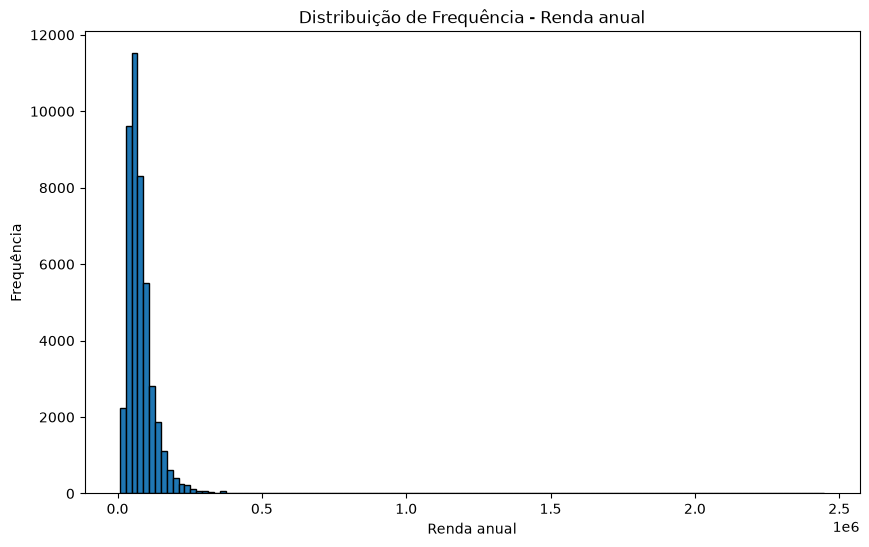

In [184]:
# Gerando um grafico dedistribuição de frequencia da variavel person_age
plt.figure(figsize=(10, 6))
plt.hist(df_inicial['Renda anual'], bins=120, edgecolor='black')
# plt.xscale('log')
plt.title('Distribuição de Frequência - Renda anual')
plt.xlabel('Renda anual')
plt.ylabel('Frequência')
plt.show()  

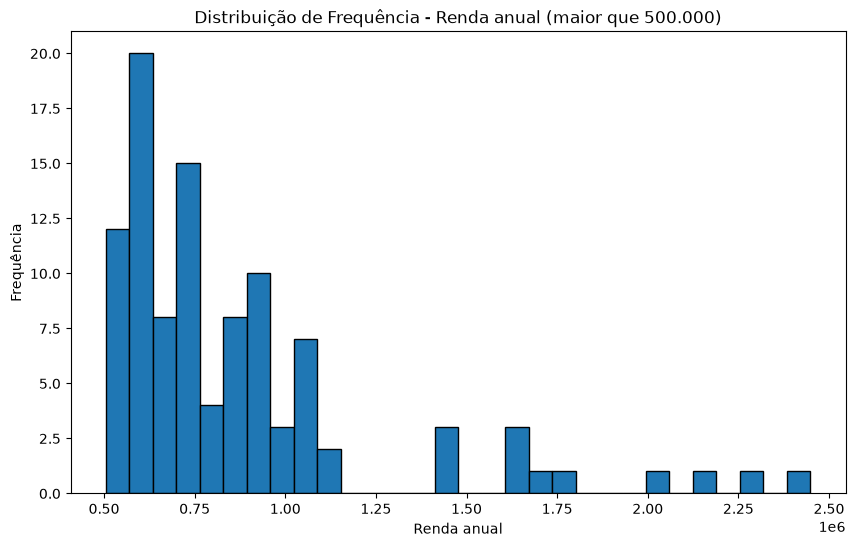

In [185]:
# Gerando um grafico de distribuição de renda anual maior que 500.000
plt.figure(figsize=(10, 6))
plt.hist(df_inicial[df_inicial['Renda anual'] > 500000]['Renda anual'], bins=30, edgecolor='black')
plt.title('Distribuição de Frequência - Renda anual (maior que 500.000)')
plt.xlabel('Renda anual')
plt.ylabel('Frequência')
plt.show()

In [186]:
df_inicial[df_inicial['Renda anual'] > 1000000]

,Idade,Sexo,Escolaridade,Renda anual,Anos de Experiência Profissional,Situação de Propriedade,Valor Emprestimo Solicitado,Finalidade do Emprestimo,Tx de Juros Emprestimo A.A.,Percentual do Emprestimo pela Renda Anual,Histórico de Crédito(em Anos),Score Pessoa,Indicador de inadimplência de Empréstimos Anteriores,Status da Aprovação do Empréstimo
17833,32.0,female,High School,1440746.0,6,MORTGAGE,12000.0,VENTURE,7.51,0.01,8.0,613,No,0
17834,34.0,male,Bachelor,1138723.0,12,MORTGAGE,2000.0,PERSONAL,9.99,0.00,7.0,609,Yes,0
29119,36.0,male,Doctorate,1440982.0,15,OWN,10000.0,MEDICAL,6.54,0.01,11.0,682,Yes,0
29120,40.0,female,Bachelor,1440915.0,19,MORTGAGE,10000.0,MEDICAL,11.01,0.01,16.0,637,Yes,0
29121,50.0,male,High School,1081082.0,28,MORTGAGE,30000.0,DEBTCONSOLIDATION,12.69,0.03,15.0,643,No,0
29122,36.0,female,High School,1081254.0,14,MORTGAGE,6000.0,PERSONAL,11.01,0.01,12.0,600,Yes,0
29345,42.0,male,High School,1067921.0,20,RENT,20000.0,EDUCATION,11.01,0.02,17.0,529,Yes,0
30049,42.0,male,High School,2448661.0,16,RENT,8450.0,VENTURE,12.29,0.00,15.0,635,Yes,0
31921,37.0,male,Associate,1081139.0,15,MORTGAGE,25000.0,PERSONAL,12.87,0.02,13.0,625,Yes,0
31922,47.0,male,High School,1635757.0,24,MORTGAGE,6600.0,VENTURE,7.74,0.00,17.0,591,Yes,0


-   As linhas com renda acima de 1 milhão são coerentes: idades de 32 a 63 anos, experiência compatível (6 a 43 anos), muitas com hipoteca ou imóvel próprio, histórico de crédito longo. Ou seja, não encontrei indicios de inconsistências.

In [187]:
# Taxa de aprovação de empréstimos por faixa de renda
bins = [0, 30_000, 60_000, 100_000, 200_000, 500_000, np.inf]

df_inicial.groupby(
    pd.cut(df_inicial['Renda anual'], bins=bins),
    observed=True
)['Status da Aprovação do Empréstimo'].agg(['mean', 'count']).rename_axis('faixa_renda')

,mean,count
faixa_renda,,
"(0.0, 30000.0]",0.562177,2903
"(30000.0, 60000.0]",0.296626,15383
"(60000.0, 100000.0]",0.171321,16688
"(100000.0, 200000.0]",0.093725,8781
"(200000.0, 500000.0]",0.095866,1137
"(500000.0, inf]",0.138614,101


-   O resultado por faixa de renda é curioso: quanto maior a renda, menor a taxa de aprovação (56% até 30 mil, cerca de 9% acima de 100 mil). Em um cenário real isso seria o oposto do esperado. Como esse dataset do Kaggle é sintético, é provável que o padrão venha da forma como os dados foram gerados, e não de uma regra de negócio realista.

In [188]:
# Estatísticas descritivas para as variáveis numéricas
df_inicial.describe().round(2)

,Idade,Renda anual,Anos de Experiência Profissional,Valor Emprestimo Solicitado,Tx de Juros Emprestimo A.A.,Percentual do Emprestimo pela Renda Anual,Histórico de Crédito(em Anos),Score Pessoa,Status da Aprovação do Empréstimo
count,44993.00,44993.00,44993.00,44993.00,44993.00,44993.00,44993.00,44993.00,44993.00
mean,27.75,79908.45,5.39,9583.18,11.01,0.14,5.87,632.59,0.22
std,5.91,63322.13,5.93,6314.80,2.98,0.09,3.88,50.40,0.42
min,20.00,8000.00,0.00,500.00,5.42,0.00,2.00,390.00,0.00
25%,24.00,47195.00,1.00,5000.00,8.59,0.07,3.00,601.00,0.00
50%,26.00,67046.00,4.00,8000.00,11.01,0.12,4.00,640.00,0.00
75%,30.00,95778.00,8.00,12237.00,12.99,0.19,8.00,670.00,0.00
max,94.00,2448661.00,76.00,35000.00,20.00,0.66,30.00,784.00,1.00


- Percentual de Emprestimo pela Renda Anual

In [189]:
# Verificando registros com percentual do empréstimo pela renda anual igual a zero
df_inicial[df_inicial["Percentual do Emprestimo pela Renda Anual"] == 0.00]

,Idade,Sexo,Escolaridade,Renda anual,Anos de Experiência Profissional,Situação de Propriedade,Valor Emprestimo Solicitado,Finalidade do Emprestimo,Tx de Juros Emprestimo A.A.,Percentual do Emprestimo pela Renda Anual,Histórico de Crédito(em Anos),Score Pessoa,Indicador de inadimplência de Empréstimos Anteriores,Status da Aprovação do Empréstimo
238,22.0,male,High School,220518.0,0,MORTGAGE,1000.0,EDUCATION,11.01,0.0,2.0,551,Yes,0
16926,22.0,male,High School,220715.0,0,MORTGAGE,1000.0,EDUCATION,11.01,0.0,2.0,577,No,0
17834,34.0,male,Bachelor,1138723.0,12,MORTGAGE,2000.0,PERSONAL,9.99,0.0,7.0,609,Yes,0
17846,30.0,male,Master,605611.0,9,RENT,3000.0,DEBTCONSOLIDATION,11.36,0.0,9.0,631,Yes,0
18917,35.0,female,Master,613103.0,10,RENT,1800.0,PERSONAL,13.48,0.0,6.0,571,No,0
27877,30.0,female,Associate,627222.0,4,MORTGAGE,2500.0,HOMEIMPROVEMENT,7.43,0.0,9.0,637,No,0
29188,41.0,male,High School,241503.0,20,MORTGAGE,1000.0,VENTURE,10.38,0.0,13.0,611,No,0
29527,36.0,female,Associate,447300.0,16,RENT,2000.0,DEBTCONSOLIDATION,11.01,0.0,14.0,638,No,1
30049,42.0,male,High School,2448661.0,16,RENT,8450.0,VENTURE,12.29,0.0,15.0,635,Yes,0
31910,41.0,male,High School,533530.0,19,MORTGAGE,2500.0,EDUCATION,15.31,0.0,11.0,667,Yes,0


-   Verificamos que não se trata de um erro. O valor do emprestimo perante a renda anual é pequena representando valores após a segunda casa decimal.

# 4.    Engenharia de Features e Preparação dos Dados para Modelagem.

In [190]:
df_inicial

,Idade,Sexo,Escolaridade,Renda anual,Anos de Experiência Profissional,Situação de Propriedade,Valor Emprestimo Solicitado,Finalidade do Emprestimo,Tx de Juros Emprestimo A.A.,Percentual do Emprestimo pela Renda Anual,Histórico de Crédito(em Anos),Score Pessoa,Indicador de inadimplência de Empréstimos Anteriores,Status da Aprovação do Empréstimo
0,22.0,female,Master,71948.0,0,RENT,35000.0,PERSONAL,16.02,0.49,3.0,561,No,1
1,21.0,female,High School,12282.0,0,OWN,1000.0,EDUCATION,11.14,0.08,2.0,504,Yes,0
2,25.0,female,High School,12438.0,3,MORTGAGE,5500.0,MEDICAL,12.87,0.44,3.0,635,No,1
3,23.0,female,Bachelor,79753.0,0,RENT,35000.0,MEDICAL,15.23,0.44,2.0,675,No,1
4,24.0,male,Master,66135.0,1,RENT,35000.0,MEDICAL,14.27,0.53,4.0,586,No,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44995,27.0,male,Associate,47971.0,6,RENT,15000.0,MEDICAL,15.66,0.31,3.0,645,No,1
44996,37.0,female,Associate,65800.0,17,RENT,9000.0,HOMEIMPROVEMENT,14.07,0.14,11.0,621,No,1
44997,33.0,male,Associate,56942.0,7,RENT,2771.0,DEBTCONSOLIDATION,10.02,0.05,10.0,668,No,1
44998,29.0,male,Bachelor,33164.0,4,RENT,12000.0,EDUCATION,13.23,0.36,6.0,604,No,1


In [191]:
# Criando uma cópia do DataFrame df_inicial para df_final
df_final = df_inicial.copy()

In [192]:
df_final

,Idade,Sexo,Escolaridade,Renda anual,Anos de Experiência Profissional,Situação de Propriedade,Valor Emprestimo Solicitado,Finalidade do Emprestimo,Tx de Juros Emprestimo A.A.,Percentual do Emprestimo pela Renda Anual,Histórico de Crédito(em Anos),Score Pessoa,Indicador de inadimplência de Empréstimos Anteriores,Status da Aprovação do Empréstimo
0,22.0,female,Master,71948.0,0,RENT,35000.0,PERSONAL,16.02,0.49,3.0,561,No,1
1,21.0,female,High School,12282.0,0,OWN,1000.0,EDUCATION,11.14,0.08,2.0,504,Yes,0
2,25.0,female,High School,12438.0,3,MORTGAGE,5500.0,MEDICAL,12.87,0.44,3.0,635,No,1
3,23.0,female,Bachelor,79753.0,0,RENT,35000.0,MEDICAL,15.23,0.44,2.0,675,No,1
4,24.0,male,Master,66135.0,1,RENT,35000.0,MEDICAL,14.27,0.53,4.0,586,No,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44995,27.0,male,Associate,47971.0,6,RENT,15000.0,MEDICAL,15.66,0.31,3.0,645,No,1
44996,37.0,female,Associate,65800.0,17,RENT,9000.0,HOMEIMPROVEMENT,14.07,0.14,11.0,621,No,1
44997,33.0,male,Associate,56942.0,7,RENT,2771.0,DEBTCONSOLIDATION,10.02,0.05,10.0,668,No,1
44998,29.0,male,Bachelor,33164.0,4,RENT,12000.0,EDUCATION,13.23,0.36,6.0,604,No,1


## 4.1.  Excluindo a coluna 'Sexo'

In [193]:
# excluindo a coluna 'Sexo' do DataFrame df_final
df_final = df_final.drop(columns=['Sexo'])

In [194]:
df_final

,Idade,Escolaridade,Renda anual,Anos de Experiência Profissional,Situação de Propriedade,Valor Emprestimo Solicitado,Finalidade do Emprestimo,Tx de Juros Emprestimo A.A.,Percentual do Emprestimo pela Renda Anual,Histórico de Crédito(em Anos),Score Pessoa,Indicador de inadimplência de Empréstimos Anteriores,Status da Aprovação do Empréstimo
0,22.0,Master,71948.0,0,RENT,35000.0,PERSONAL,16.02,0.49,3.0,561,No,1
1,21.0,High School,12282.0,0,OWN,1000.0,EDUCATION,11.14,0.08,2.0,504,Yes,0
2,25.0,High School,12438.0,3,MORTGAGE,5500.0,MEDICAL,12.87,0.44,3.0,635,No,1
3,23.0,Bachelor,79753.0,0,RENT,35000.0,MEDICAL,15.23,0.44,2.0,675,No,1
4,24.0,Master,66135.0,1,RENT,35000.0,MEDICAL,14.27,0.53,4.0,586,No,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
44995,27.0,Associate,47971.0,6,RENT,15000.0,MEDICAL,15.66,0.31,3.0,645,No,1
44996,37.0,Associate,65800.0,17,RENT,9000.0,HOMEIMPROVEMENT,14.07,0.14,11.0,621,No,1
44997,33.0,Associate,56942.0,7,RENT,2771.0,DEBTCONSOLIDATION,10.02,0.05,10.0,668,No,1
44998,29.0,Bachelor,33164.0,4,RENT,12000.0,EDUCATION,13.23,0.36,6.0,604,No,1


## 4.2. Aplicando One Hot Encoding para as váriáves não numéricas (menos Score Pessoa)

In [195]:
# Para facilitar a leitura, vamos traduzir os valores das variáveis não numéricas para português.
traducao_escolaridade = {
    'High School': 'Ensino Médio',
    'Associate': 'Técnico',
    'Bachelor': 'Graduação',
    'Master': 'Mestrado',
    'Doctorate': 'Doutorado'
}

traducao_propriedade = {
    'RENT': 'Aluguel',
    'OWN': 'Própria',
    'MORTGAGE': 'Financiada',
    'OTHER': 'Outra'
}

traducao_finalidade = {
    'PERSONAL': 'Pessoal',
    'EDUCATION': 'Educação',
    'MEDICAL': 'Médica',
    'VENTURE': 'Empreendimento',
    'HOMEIMPROVEMENT': 'Reforma do Imóvel',
    'DEBTCONSOLIDATION': 'Consolidação de Dívidas'
}

df_final['Escolaridade'] = df_final['Escolaridade'].replace(traducao_escolaridade)
df_final['Situação de Propriedade'] = df_final['Situação de Propriedade'].replace(traducao_propriedade)
df_final['Finalidade do Emprestimo'] = df_final['Finalidade do Emprestimo'].replace(traducao_finalidade)

In [196]:
# Aplicando One Hot Encoding nas variáveis Escolaridade, Situação de Propriedade e Finalidade do Empréstimo.
colunas_ohe = ['Escolaridade', 'Situação de Propriedade', 'Finalidade do Emprestimo']

df_final = pd.get_dummies(df_final, columns=colunas_ohe, drop_first=True, dtype=int)

df_final.head()


,Idade,Renda anual,Anos de Experiência Profissional,Valor Emprestimo Solicitado,Tx de Juros Emprestimo A.A.,Percentual do Emprestimo pela Renda Anual,Histórico de Crédito(em Anos),Score Pessoa,Indicador de inadimplência de Empréstimos Anteriores,Status da Aprovação do Empréstimo,Escolaridade_Ensino Médio,Escolaridade_Graduação,Escolaridade_Mestrado,Escolaridade_Técnico,Situação de Propriedade_Financiada,Situação de Propriedade_Outra,Situação de Propriedade_Própria,Finalidade do Emprestimo_Educação,Finalidade do Emprestimo_Empreendimento,Finalidade do Emprestimo_Médica,Finalidade do Emprestimo_Pessoal,Finalidade do Emprestimo_Reforma do Imóvel
0,22.0,71948.0,0,35000.0,16.02,0.49,3.0,561,No,1,0,0,1,0,0,0,0,0,0,0,1,0
1,21.0,12282.0,0,1000.0,11.14,0.08,2.0,504,Yes,0,1,0,0,0,0,0,1,1,0,0,0,0
2,25.0,12438.0,3,5500.0,12.87,0.44,3.0,635,No,1,1,0,0,0,1,0,0,0,0,1,0,0
3,23.0,79753.0,0,35000.0,15.23,0.44,2.0,675,No,1,0,1,0,0,0,0,0,0,0,1,0,0
4,24.0,66135.0,1,35000.0,14.27,0.53,4.0,586,No,1,0,0,1,0,0,0,0,0,0,1,0,0


## 4.3. Aplicando Codificação Binária para a Variável Score Pessoa

    - Será 0 para Indicador de inadimplência de Empréstimos Anteriores = 'No'
    - Será 1 para Indicador de inadimplência de Empréstimos Anteriores = 'Yes'

In [197]:
# Convertendo a variável 'Indicador de inadimplência de Empréstimos Anteriores' para valores binários (0 e 1)
df_final['Indicador de inadimplência de Empréstimos Anteriores'] = (df_final['Indicador de inadimplência de Empréstimos Anteriores'].map({'No': 0, 'Yes': 1})
)

pd.set_option('display.max_columns', None) # Evitar o truncamento das colunas ao exibir o DataFrame

df_final.head()

,Idade,Renda anual,Anos de Experiência Profissional,Valor Emprestimo Solicitado,Tx de Juros Emprestimo A.A.,Percentual do Emprestimo pela Renda Anual,Histórico de Crédito(em Anos),Score Pessoa,Indicador de inadimplência de Empréstimos Anteriores,Status da Aprovação do Empréstimo,Escolaridade_Ensino Médio,Escolaridade_Graduação,Escolaridade_Mestrado,Escolaridade_Técnico,Situação de Propriedade_Financiada,Situação de Propriedade_Outra,Situação de Propriedade_Própria,Finalidade do Emprestimo_Educação,Finalidade do Emprestimo_Empreendimento,Finalidade do Emprestimo_Médica,Finalidade do Emprestimo_Pessoal,Finalidade do Emprestimo_Reforma do Imóvel
0,22.0,71948.0,0,35000.0,16.02,0.49,3.0,561,0,1,0,0,1,0,0,0,0,0,0,0,1,0
1,21.0,12282.0,0,1000.0,11.14,0.08,2.0,504,1,0,1,0,0,0,0,0,1,1,0,0,0,0
2,25.0,12438.0,3,5500.0,12.87,0.44,3.0,635,0,1,1,0,0,0,1,0,0,0,0,1,0,0
3,23.0,79753.0,0,35000.0,15.23,0.44,2.0,675,0,1,0,1,0,0,0,0,0,0,0,1,0,0
4,24.0,66135.0,1,35000.0,14.27,0.53,4.0,586,0,1,0,0,1,0,0,0,0,0,0,1,0,0


In [198]:
# Verificando as estatísticas descritivas do DataFrame final
df_final.describe().round(2)

,Idade,Renda anual,Anos de Experiência Profissional,Valor Emprestimo Solicitado,Tx de Juros Emprestimo A.A.,Percentual do Emprestimo pela Renda Anual,Histórico de Crédito(em Anos),Score Pessoa,Indicador de inadimplência de Empréstimos Anteriores,Status da Aprovação do Empréstimo,Escolaridade_Ensino Médio,Escolaridade_Graduação,Escolaridade_Mestrado,Escolaridade_Técnico,Situação de Propriedade_Financiada,Situação de Propriedade_Outra,Situação de Propriedade_Própria,Finalidade do Emprestimo_Educação,Finalidade do Emprestimo_Empreendimento,Finalidade do Emprestimo_Médica,Finalidade do Emprestimo_Pessoal,Finalidade do Emprestimo_Reforma do Imóvel
count,44993.00,44993.00,44993.00,44993.00,44993.00,44993.00,44993.00,44993.00,44993.00,44993.00,44993.00,44993.00,44993.00,44993.00,44993.00,44993.00,44993.00,44993.0,44993.00,44993.00,44993.00,44993.00
mean,27.75,79908.45,5.39,9583.18,11.01,0.14,5.87,632.59,0.51,0.22,0.27,0.30,0.16,0.27,0.41,0.00,0.07,0.2,0.17,0.19,0.17,0.11
std,5.91,63322.13,5.93,6314.80,2.98,0.09,3.88,50.40,0.50,0.42,0.44,0.46,0.36,0.44,0.49,0.05,0.25,0.4,0.38,0.39,0.37,0.31
min,20.00,8000.00,0.00,500.00,5.42,0.00,2.00,390.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00
25%,24.00,47195.00,1.00,5000.00,8.59,0.07,3.00,601.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00
50%,26.00,67046.00,4.00,8000.00,11.01,0.12,4.00,640.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00
75%,30.00,95778.00,8.00,12237.00,12.99,0.19,8.00,670.00,1.00,0.00,1.00,1.00,0.00,1.00,1.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00
max,94.00,2448661.00,76.00,35000.00,20.00,0.66,30.00,784.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.0,1.00,1.00,1.00,1.00


In [199]:
df_final.info()

<class 'pandas.DataFrame'>
Index: 44993 entries, 0 to 44999
Data columns (total 22 columns):
 #   Column                                                Non-Null Count  Dtype  
---  ------                                                --------------  -----  
 0   Idade                                                 44993 non-null  float64
 1   Renda anual                                           44993 non-null  float64
 2   Anos de Experiência Profissional                      44993 non-null  int64  
 3   Valor Emprestimo Solicitado                           44993 non-null  float64
 4   Tx de Juros Emprestimo A.A.                           44993 non-null  float64
 5   Percentual do Emprestimo pela Renda Anual             44993 non-null  float64
 6   Histórico de Crédito(em Anos)                         44993 non-null  float64
 7   Score Pessoa                                          44993 non-null  int64  
 8   Indicador de inadimplência de Empréstimos Anteriores  44993 non-null  in

## 4.4. Salvando o df_final em um arquivo CSV

In [200]:
# Salvando o DataFrame final em um arquivo CSV
df_final.to_csv('df_final.csv', index=False)

# 5.    Criação do Modelo de Regressão Logistica

    -   Status da Aprovação do empréstimo será nosso Target

| Modelo | Atributos | Observação |
|---|---|---|
| **M0** Baseline | nenhum (sempre prevê "Reprovado") | o modelo "burro": 77,8% da Base Reprovada |
| **M1** Logística Múltipla | todas as variáveis numéricas brutas (21) | sem feature engineering |
| **M2** Logistica Múltipla | seleção de 3 variáveis | escolha das varíavel com maiores correlação |
| **M3** Logistica Múltipla | seleção de 13 varíaveis | exclusão das váriaveis menos representativas |


## 5.1.  Separando treino e teste

-   Treinamos o modelo com **75%** dos clientes e testamos nos **25%** restantes, que o modelo nunca viu. Primeiro, separamos o que é **atributo** (`X`) do que é **resposta** (`y`)

In [201]:
# Carregando o DataFrame final a partir do arquivo CSV
df = pd.read_csv('df_final.csv')

In [202]:
df

,Idade,Renda anual,Anos de Experiência Profissional,Valor Emprestimo Solicitado,Tx de Juros Emprestimo A.A.,Percentual do Emprestimo pela Renda Anual,Histórico de Crédito(em Anos),Score Pessoa,Indicador de inadimplência de Empréstimos Anteriores,Status da Aprovação do Empréstimo,Escolaridade_Ensino Médio,Escolaridade_Graduação,Escolaridade_Mestrado,Escolaridade_Técnico,Situação de Propriedade_Financiada,Situação de Propriedade_Outra,Situação de Propriedade_Própria,Finalidade do Emprestimo_Educação,Finalidade do Emprestimo_Empreendimento,Finalidade do Emprestimo_Médica,Finalidade do Emprestimo_Pessoal,Finalidade do Emprestimo_Reforma do Imóvel
0,22.0,71948.0,0,35000.0,16.02,0.49,3.0,561,0,1,0,0,1,0,0,0,0,0,0,0,1,0
1,21.0,12282.0,0,1000.0,11.14,0.08,2.0,504,1,0,1,0,0,0,0,0,1,1,0,0,0,0
2,25.0,12438.0,3,5500.0,12.87,0.44,3.0,635,0,1,1,0,0,0,1,0,0,0,0,1,0,0
3,23.0,79753.0,0,35000.0,15.23,0.44,2.0,675,0,1,0,1,0,0,0,0,0,0,0,1,0,0
4,24.0,66135.0,1,35000.0,14.27,0.53,4.0,586,0,1,0,0,1,0,0,0,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44988,27.0,47971.0,6,15000.0,15.66,0.31,3.0,645,0,1,0,0,0,1,0,0,0,0,0,1,0,0
44989,37.0,65800.0,17,9000.0,14.07,0.14,11.0,621,0,1,0,0,0,1,0,0,0,0,0,0,0,1
44990,33.0,56942.0,7,2771.0,10.02,0.05,10.0,668,0,1,0,0,0,1,0,0,0,0,0,0,0,0
44991,29.0,33164.0,4,12000.0,13.23,0.36,6.0,604,0,1,0,1,0,0,0,0,0,1,0,0,0,0


In [203]:
# Dividindo os dados em variáveis independentes (X) e variável dependente (y)
y = df_final['Status da Aprovação do Empréstimo']
X = df_final.drop(columns='Status da Aprovação do Empréstimo')

print(X.shape, y.shape)
print(X.select_dtypes(include='object').columns.tolist())   # deve ser lista vazia

(44993, 21) (44993,)
[]


In [204]:
# Esta célula divide os clientes em treino (75%) e teste (25%), mantendo a mesma proporção de Reprovado nos dois.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

print(y_train.value_counts(normalize=True).round(3))
print(y_test.value_counts(normalize=True).round(3))

Status da Aprovação do Empréstimo
0    0.778
1    0.222
Name: proportion, dtype: float64
Status da Aprovação do Empréstimo
0    0.778
1    0.222
Name: proportion, dtype: float64


In [205]:
# verificando a quantidade de registros de treino e teste
qtde_treino = y_train.shape[0]
qtde_teste = y_test.shape[0]

print(f'Quantidade de registros de treino: {qtde_treino}')
print(f'Quantidade de registros de teste: {qtde_teste}')

Quantidade de registros de treino: 33744
Quantidade de registros de teste: 11249


## 5.2. Modelo M0 - Baseline no Conjunto de Teste

In [206]:
# Cria o modelo burro: sempre prevê a classe mais frequente do treino
dummy = DummyClassifier(strategy='most_frequent')

# 2. "Treina": ele só descobre qual é a classe majoritária em y_train (0)
dummy.fit(X_train, y_train)

# 3. Prediz no teste: devolve 0 para todas as 11.249 linhas
y_pred_dummy = dummy.predict(X_test)

# 4. Avalia no teste
acc_baseline = accuracy_score(y_test, y_pred_dummy)
rec_baseline = recall_score(y_test, y_pred_dummy)        # recall da classe 1
f1_baseline = f1_score(y_test, y_pred_dummy)             # F1 da classe 1

print(f'Acurácia do baseline: {acc_baseline:.4f}')
print(f'Recall (classe aprovado): {rec_baseline:.4f}')
print(f'F1 (classe aprovado): {f1_baseline:.4f}')

Acurácia do baseline: 0.7778
Recall (classe aprovado): 0.0000
F1 (classe aprovado): 0.0000


## 5.3. Padronização as variáveis numéricas.

    -   Só as contínuas, ajustando o scaler no treino

In [207]:
# Padronizando as variáveis numéricas para que tenham média 0 e desvio padrão 1
colunas_num = ['Idade', 'Renda anual', 'Anos de Experiência Profissional',
               'Valor Emprestimo Solicitado', 'Tx de Juros Emprestimo A.A.',
               'Percentual do Emprestimo pela Renda Anual',
               'Histórico de Crédito(em Anos)', 'Score Pessoa']

scaler = StandardScaler()
X_train_s = X_train.copy()
X_test_s = X_test.copy()
X_train_s[colunas_num] = scaler.fit_transform(X_train[colunas_num])
X_test_s[colunas_num] = scaler.transform(X_test[colunas_num])

In [208]:
# Verificando os primeiros registros do conjunto de treino padronizado
X_train_s.head(5)

,Idade,Renda anual,Anos de Experiência Profissional,Valor Emprestimo Solicitado,Tx de Juros Emprestimo A.A.,Percentual do Emprestimo pela Renda Anual,Histórico de Crédito(em Anos),Score Pessoa,Indicador de inadimplência de Empréstimos Anteriores,Escolaridade_Ensino Médio,Escolaridade_Graduação,Escolaridade_Mestrado,Escolaridade_Técnico,Situação de Propriedade_Financiada,Situação de Propriedade_Outra,Situação de Propriedade_Própria,Finalidade do Emprestimo_Educação,Finalidade do Emprestimo_Empreendimento,Finalidade do Emprestimo_Médica,Finalidade do Emprestimo_Pessoal,Finalidade do Emprestimo_Reforma do Imóvel
41186,1.902416,1.563976,1.788128,0.387476,0.025877,-0.797691,2.871131,0.921696,1,1,0,0,0,1,0,0,0,0,0,0,1
4847,-0.296876,-0.561309,-0.236878,-0.725757,-0.212742,-0.337934,-0.484113,0.842158,0,0,0,0,1,0,0,0,0,1,0,0,0
44303,-0.635228,0.006986,-0.574379,1.659741,1.124868,1.271215,-0.484113,-1.504204,0,0,1,0,0,0,0,0,0,0,0,0,0
1042,-0.296876,0.262727,-0.743129,1.341675,0.956826,0.581580,-0.742209,0.563776,1,1,0,0,0,0,0,0,0,0,0,0,1
44893,-0.804404,-0.949632,-0.911880,-0.715738,0.143506,1.501094,-0.484113,-0.947440,0,0,0,0,1,0,0,0,0,0,0,1,0


In [209]:
# Verificando os primeiros registros do conjunto de teste padronizado
X_test_s.head(5)

,Idade,Renda anual,Anos de Experiência Profissional,Valor Emprestimo Solicitado,Tx de Juros Emprestimo A.A.,Percentual do Emprestimo pela Renda Anual,Histórico de Crédito(em Anos),Score Pessoa,Indicador de inadimplência de Empréstimos Anteriores,Escolaridade_Ensino Médio,Escolaridade_Graduação,Escolaridade_Mestrado,Escolaridade_Técnico,Situação de Propriedade_Financiada,Situação de Propriedade_Outra,Situação de Propriedade_Própria,Finalidade do Emprestimo_Educação,Finalidade do Emprestimo_Empreendimento,Finalidade do Emprestimo_Médica,Finalidade do Emprestimo_Pessoal,Finalidade do Emprestimo_Reforma do Imóvel
42076,-0.804404,-0.390049,-0.236878,-1.043823,-0.088391,-1.027569,-0.484113,-2.438771,1,0,0,0,1,1,0,0,0,0,1,0,0
30595,1.394887,-0.591850,1.619378,-0.248657,2.264189,0.581580,2.871131,0.981349,0,0,1,0,0,0,0,0,0,0,0,0,1
24829,0.379829,0.443303,-0.405628,0.069409,1.067734,-0.567812,1.064461,0.265510,1,0,0,0,1,0,0,0,1,0,0,0,0
18677,1.056534,-0.760703,0.944376,-1.361890,-0.461444,-1.257448,0.032078,-0.152063,1,0,1,0,0,1,0,0,0,0,0,0,0
16858,-0.804404,-0.148453,-0.068127,-0.248657,0.876167,-0.337934,-0.484113,0.802389,1,0,1,0,0,1,0,0,0,1,0,0,0


## 5.4. Modelo M1 -  Com todas as varíaveis 21 Variáveis do DF

In [210]:
# Criando o modelo de regressão logística com todas as variáveis (M1)
modelo_M1 = LogisticRegression(max_iter=1000, random_state=42)
modelo_M1.fit(X_train_s, y_train)

y_pred = modelo_M1.predict(X_test_s)
y_proba = modelo_M1.predict_proba(X_test_s)[:, 1]

In [211]:
modelo_M1

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

## 5.5. Avaliar e Comparar com o Baseline

In [212]:
# Avaliando o modelo de regressão logística (M1) no conjunto de teste
print(f'Acurácia: {accuracy_score(y_test, y_pred):.4f}')
print(f'ROC-AUC: {roc_auc_score(y_test, y_proba):.4f}')
print(classification_report(y_test, y_pred))

Acurácia: 0.8940
ROC-AUC: 0.9522
              precision    recall  f1-score   support

           0       0.93      0.94      0.93      8749
           1       0.77      0.74      0.76      2500

    accuracy                           0.89     11249
   macro avg       0.85      0.84      0.84     11249
weighted avg       0.89      0.89      0.89     11249



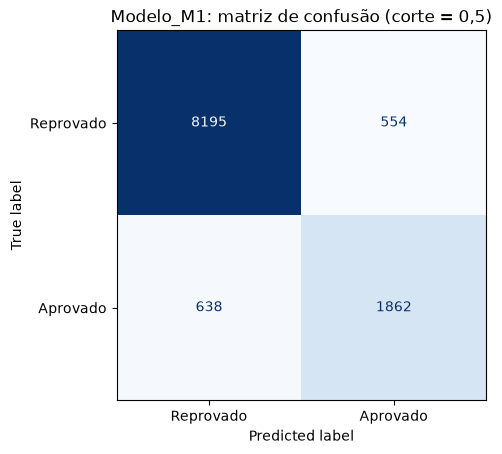

In [213]:

# Matriz de confusao com as previsoes calculadas o modelo M1, utilizando o corte de 0,5 para classificar as previsões.
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Reprovado", "Aprovado"],
                                        cmap="Blues", colorbar=False)
plt.grid(False)
plt.title("Modelo_M1: matriz de confusão (corte = 0,5)")
plt.show()

In [214]:
# Analisando os parâmetros (coeficientes)
coef = pd.DataFrame({
    'variavel': X_train_s.columns,
    'coeficiente': modelo_M1.coef_[0],
    'odds_ratio': np.exp(modelo_M1.coef_[0])
})
coef['abs'] = coef['coeficiente'].abs()
coef = coef.sort_values('abs', ascending=False).drop(columns='abs')

print('Intercepto:', modelo_M1.intercept_[0].round(4))
print(coef.round(4).to_string(index=False))

Intercepto: 0.2592
                                            variavel  coeficiente  odds_ratio
Indicador de inadimplência de Empréstimos Anteriores      -7.7944      0.0004
                     Situação de Propriedade_Própria      -2.0770      0.1253
           Percentual do Emprestimo pela Renda Anual       1.4442      4.2387
             Finalidade do Emprestimo_Empreendimento      -1.2641      0.2825
                         Tx de Juros Emprestimo A.A.       0.9940      2.7019
                   Finalidade do Emprestimo_Educação      -0.9289      0.3950
                  Situação de Propriedade_Financiada      -0.7568      0.4692
                    Finalidade do Emprestimo_Pessoal      -0.7299      0.4819
                         Valor Emprestimo Solicitado      -0.6824      0.5054
                                        Score Pessoa      -0.4544      0.6348
                     Finalidade do Emprestimo_Médica      -0.2667      0.7659
                                         Rend

-   O coeficiente mais relevante é o do indicador de inadimplência prévia (OR ≈ 0,0004), que praticamente determina a reprovação. Entre as variáveis numéricas padronizadas, destacam-se o percentual do empréstimo sobre a renda (OR ≈ 4,2) e a taxa de juros (OR ≈ 2,7). Variáveis de escolaridade, idade, experiência e histórico de crédito têm efeito pequeno. 
-   Alguns sinais são contraintuitivos do ponto de vista de negócio, o que é compatível com a natureza sintética da base, e os coeficientes de renda, valor e percentual do empréstimo devem ser lidos com cautela por conta da possível multicolinearidade.

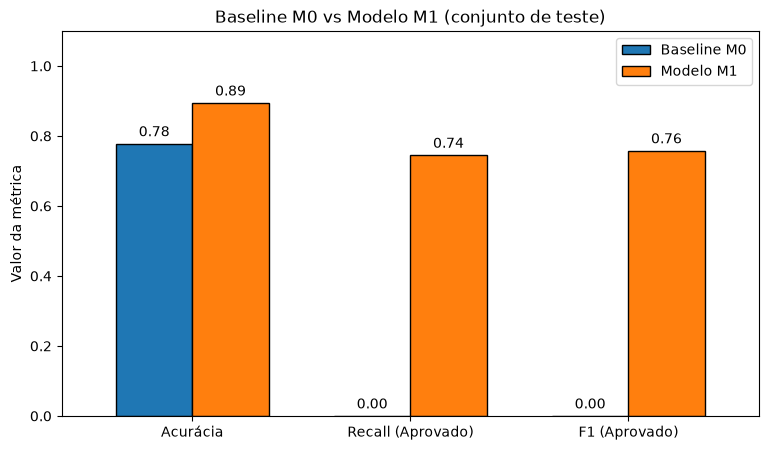

In [215]:
# Comparando as métricas do baseline M0 com o modelo M1
metricas = pd.DataFrame({
    'Baseline M0': [accuracy_score(y_test, y_pred_dummy),
                     recall_score(y_test, y_pred_dummy),
                     f1_score(y_test, y_pred_dummy, zero_division=0)],
    'Modelo M1': [accuracy_score(y_test, y_pred),
                  recall_score(y_test, y_pred),
                  f1_score(y_test, y_pred)]
}, index=['Acurácia', 'Recall (Aprovado)', 'F1 (Aprovado)'])

ax = metricas.plot(kind='bar', figsize=(9, 5), width=0.7, edgecolor='black')
for c in ax.containers:
    ax.bar_label(c, fmt='%.2f', padding=3)
plt.title('Baseline M0 vs Modelo M1 (conjunto de teste)')
plt.ylabel('Valor da métrica')
plt.ylim(0, 1.1)
plt.xticks(rotation=0)
plt.legend(title='')
plt.show()

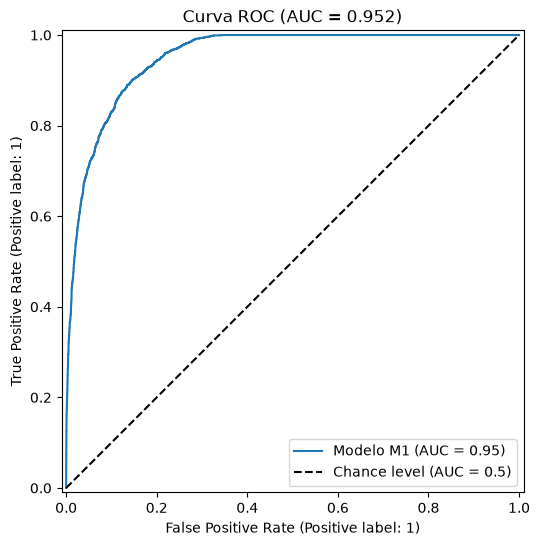

In [216]:
# Curva ROC do modelo M1
fig, ax = plt.subplots(figsize=(6, 6))
RocCurveDisplay.from_predictions(y_test, y_proba, ax=ax,
                                 name='Modelo M1', plot_chance_level=True)
plt.title(f'Curva ROC (AUC = {roc_auc_score(y_test, y_proba):.3f})')
plt.show()

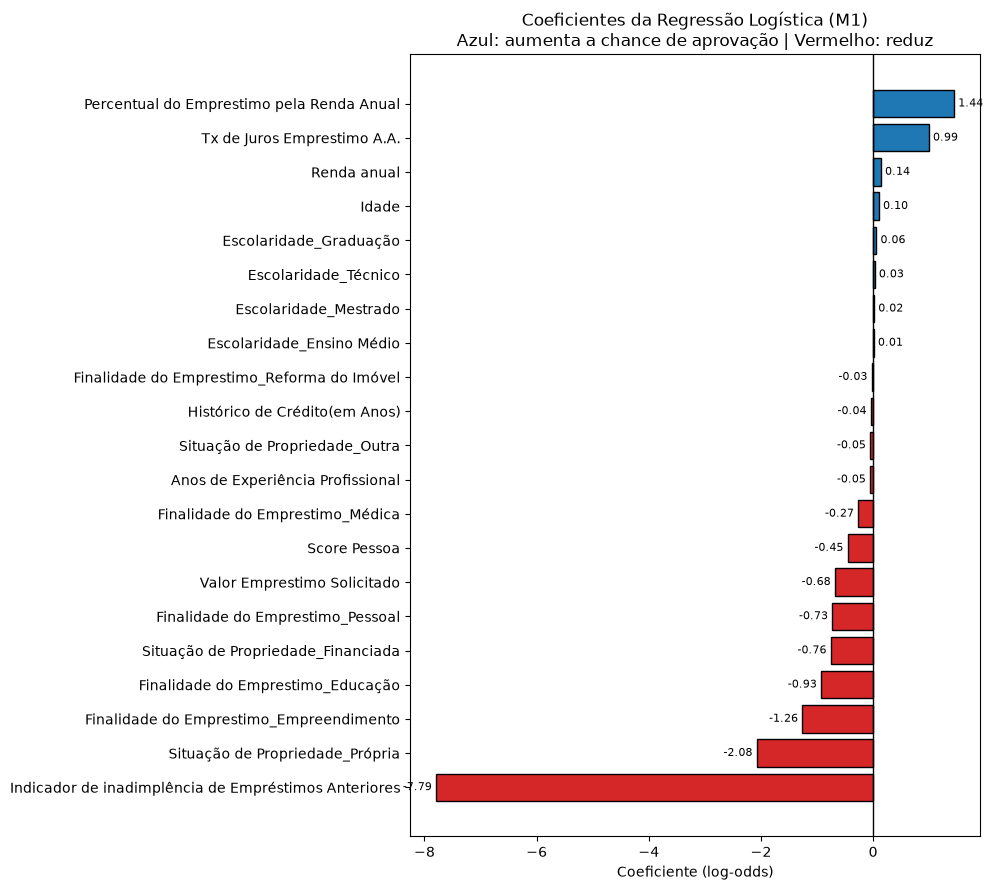

In [217]:
# Gráfico dos coeficientes do modelo M1
c = coef.sort_values('coeficiente')
cores = ['#d62728' if v < 0 else '#1f77b4' for v in c['coeficiente']]
plt.figure(figsize=(10, 9))
barras = plt.barh(c['variavel'], c['coeficiente'], color=cores, edgecolor='black')
plt.bar_label(barras, fmt='%.2f', padding=3, fontsize=8)
plt.axvline(0, color='black', linewidth=1)
plt.title('Coeficientes da Regressão Logística (M1)\nAzul: aumenta a chance de aprovação | Vermelho: reduz')
plt.xlabel('Coeficiente (log-odds)')
plt.tight_layout()
plt.show()

## 5.6. Modelo M2 - Seleção de Variáveis com Melhores Coeficientes e que não estejam codificadas com One Hot Ecoding
    -   O objetivo é verificar se conseguimos um modelo mais otimizado e que apresente bons indices de acurácia.

    -   Para esse modelo iremos utilizar as seguintes variáveis:
        -   Indicador de inadimplência de Emprestimos Anteiores
        -   Percentual do emprestimo pela renda anual
        -   Tx de juros emprestimo A.A.

In [218]:
# Selecionando as variáveis mais importantes do modelo M1 para criar o modelo M2
vars_M2 = ['Indicador de inadimplência de Empréstimos Anteriores',
           'Percentual do Emprestimo pela Renda Anual',
           'Tx de Juros Emprestimo A.A.']

print(f'Variáveis do Modelo M2: {vars_M2}')

Variáveis do Modelo M2: ['Indicador de inadimplência de Empréstimos Anteriores', 'Percentual do Emprestimo pela Renda Anual', 'Tx de Juros Emprestimo A.A.']


In [219]:
# Criando o modelo M2 com apenas 3 variáveis:
# Indicador de inadimplência, Percentual do empréstimo pela renda e Taxa de juros
vars_M2 = ['Indicador de inadimplência de Empréstimos Anteriores',
           'Percentual do Emprestimo pela Renda Anual',
           'Tx de Juros Emprestimo A.A.']

X_train_M2 = X_train_s[vars_M2]
X_test_M2 = X_test_s[vars_M2]

modelo_M2 = LogisticRegression(max_iter=1000, random_state=42)
modelo_M2.fit(X_train_M2, y_train)

y_pred_M2 = modelo_M2.predict(X_test_M2)
y_proba_M2 = modelo_M2.predict_proba(X_test_M2)[:, 1]

In [220]:
modelo_M2

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [221]:
# Avaliando o modelo M2
print(f'Acurácia M2: {accuracy_score(y_test, y_pred_M2):.4f}')
print(f'ROC-AUC M2: {roc_auc_score(y_test, y_proba_M2):.4f}')
print(classification_report(y_test, y_pred_M2))

Acurácia M2: 0.8767
ROC-AUC M2: 0.9340
              precision    recall  f1-score   support

           0       0.91      0.93      0.92      8749
           1       0.74      0.70      0.71      2500

    accuracy                           0.88     11249
   macro avg       0.82      0.81      0.82     11249
weighted avg       0.87      0.88      0.88     11249



In [222]:
# Comparando as métricas do modelo M1 com o modelo M2
comparacao = pd.DataFrame({
    'Acurácia': [accuracy_score(y_test, y_pred), accuracy_score(y_test, y_pred_M2)],
    'ROC-AUC': [roc_auc_score(y_test, y_proba), roc_auc_score(y_test, y_proba_M2)],
    'Recall (Aprovado)': [recall_score(y_test, y_pred), recall_score(y_test, y_pred_M2)],
    'F1 (Aprovado)': [f1_score(y_test, y_pred), f1_score(y_test, y_pred_M2)],
}, index=['M1 (21 variáveis)', 'M2 (3 variáveis)']).round(4)
comparacao

,Acurácia,ROC-AUC,Recall (Aprovado),F1 (Aprovado)
M1 (21 variáveis),0.8940,0.9522,0.7448,0.7575
M2 (3 variáveis),0.8767,0.9340,0.6956,0.7149


## 5.7. Busca de Novas Variáveis importantes 

In [223]:
# Avaliando a significância estatística das variáveis do modelo M1
Xc_train = sm.add_constant(X_train_s.astype(float))
logit_M1 = sm.Logit(y_train, Xc_train).fit(disp=False)

tabela = pd.DataFrame({
    'coeficiente': logit_M1.params,
    'erro_padrao': logit_M1.bse,
    'p_valor': logit_M1.pvalues,
    'IC_2.5%': logit_M1.conf_int()[0],
    'IC_97.5%': logit_M1.conf_int()[1],
    'odds_ratio': np.exp(logit_M1.params)
})
tabela['significativa (5%)'] = np.where(tabela['p_valor'] < 0.05, 'Sim', 'Não')

print(tabela.sort_values('p_valor').round(4).to_string())
print('\nPseudo R² (McFadden):', round(logit_M1.prsquared, 4))

                                                      coeficiente  erro_padrao  p_valor    IC_2.5%   IC_97.5%  odds_ratio significativa (5%)
Percentual do Emprestimo pela Renda Anual                  1.4552       0.0363   0.0000     1.3841     1.5263      4.2852                Sim
Tx de Juros Emprestimo A.A.                                0.9980       0.0227   0.0000     0.9535     1.0425      2.7129                Sim
Valor Emprestimo Solicitado                               -0.6889       0.0342   0.0000    -0.7560    -0.6218      0.5021                Sim
Score Pessoa                                              -0.4609       0.0242   0.0000    -0.5084    -0.4134      0.6307                Sim
Situação de Propriedade_Própria                           -2.1144       0.1118   0.0000    -2.3336    -1.8953      0.1207                Sim
Finalidade do Emprestimo_Empreendimento                   -1.2762       0.0740   0.0000    -1.4211    -1.1312      0.2791                Sim
Situação de P

In [224]:
# Avaliando a multicolinearidade das variáveis do modelo M1
vif = pd.DataFrame({
    'variavel': Xc_train.columns,
    'VIF': [variance_inflation_factor(Xc_train.values, i) for i in range(Xc_train.shape[1])]
})
print(vif[vif['variavel'] != 'const'].sort_values('VIF', ascending=False).round(2).to_string(index=False))

                                            variavel   VIF
                              Escolaridade_Graduação 15.78
                           Escolaridade_Ensino Médio 14.90
                                Escolaridade_Técnico 14.86
                                               Idade 13.96
                    Anos de Experiência Profissional 10.81
                               Escolaridade_Mestrado 10.25
                       Histórico de Crédito(em Anos)  4.35
           Percentual do Emprestimo pela Renda Anual  2.65
                         Valor Emprestimo Solicitado  2.65
                   Finalidade do Emprestimo_Educação  1.83
                                         Renda anual  1.79
                     Finalidade do Emprestimo_Médica  1.79
             Finalidade do Emprestimo_Empreendimento  1.77
                    Finalidade do Emprestimo_Pessoal  1.73
          Finalidade do Emprestimo_Reforma do Imóvel  1.51
                  Situação de Propriedade_Financiada  1.

## 5.8. Modelo M3 - Seleção de 13 Variáveis (Excluindo 8 Menos Representativas)

    -   Manter apenas as variáveis significativas mais a inadimplência. 
    -   Para dummies, o critério é manter o grupo inteiro se alguma categoria for significativa (Propriedade e Finalidade ficam completas; Escolaridade sai inteira).
    -   Renda Anual sai também devido a baixa representatividade e para evitar multicolinearidade 
    -   Variáveis escolhidas:
        -   Indicador de inadimplência de Empréstimos Anteriores
        -   Percentual do Emprestimo pela Renda Anual
        -   Tx de Juros Emprestimo A.A.
        -   Valor Emprestimo Solicitado
        -   Score Pessoa
        -   Situação de Propriedade
        -   Finalidade do Emprestimo

In [225]:
# Criando o modelo M3 com 13 variáveis (as 3 mais importantes do M2 + 10 variáveis dummies)
vars_M3 = [
    'Indicador de inadimplência de Empréstimos Anteriores',
    'Percentual do Emprestimo pela Renda Anual',
    'Tx de Juros Emprestimo A.A.',
    'Valor Emprestimo Solicitado',
    'Score Pessoa',
] + [c for c in X_train_s.columns if c.startswith(('Situação de Propriedade_', 'Finalidade do Emprestimo_'))]

modelo_M3 = LogisticRegression(max_iter=1000, random_state=42)
modelo_M3.fit(X_train_s[vars_M3], y_train)

y_pred_M3 = modelo_M3.predict(X_test_s[vars_M3])
y_proba_M3 = modelo_M3.predict_proba(X_test_s[vars_M3])[:, 1]

comparacao = pd.DataFrame({
    'Acurácia': [accuracy_score(y_test, p) for p in (y_pred, y_pred_M2, y_pred_M3)],
    'ROC-AUC': [roc_auc_score(y_test, p) for p in (y_proba, y_proba_M2, y_proba_M3)],
    'Recall (Aprovado)': [recall_score(y_test, p) for p in (y_pred, y_pred_M2, y_pred_M3)],
    'F1 (Aprovado)': [f1_score(y_test, p) for p in (y_pred, y_pred_M2, y_pred_M3)],
}, index=['M1 (21 variáveis)', 'M2 (3 variáveis)', 'M3 (13 variáveis)']).round(4)
comparacao

,Acurácia,ROC-AUC,Recall (Aprovado),F1 (Aprovado)
M1 (21 variáveis),0.8940,0.9522,0.7448,0.7575
M2 (3 variáveis),0.8767,0.9340,0.6956,0.7149
M3 (13 variáveis),0.8934,0.9522,0.7444,0.7564


- **Analisando o Resultado**

    -   O M3 praticamente empata com o M1: perde 0,0006 de acurácia, 0,0004 de recall e 0,0011 de F1, com AUC idêntico. Ou seja, as 10 variáveis removidas (escolaridade, idade, experiência, histórico de crédito e renda) não traziam informação preditiva relevantes. Já o M2 mostra que cortar demais custa caro: as variáveis de propriedade, finalidade, valor e score têm contribuição real.

    -   O modelo M3, obtido pela seleção de variáveis com base em p-valores (statsmodels) e VIF, manteve o desempenho do modelo completo (AUC 0,9522; acurácia 0,8934 contra 0,8940), com quase a metade das variáevis. O modelo M2, com apenas 3 variáveis, apresentou queda relevante (AUC 0,9340; recall 0,6956), indicando que as variáveis adicionais do M3 contribuem para a previsão.

    -   Pelo critério da parcimônia, o M3 foi escolhido como modelo final, mas tentaremos melhora-lo.

In [226]:
# Validação cruzada do M3, para confirmar que o resultado é estável e não depende deste split
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
res = cross_validate(LogisticRegression(max_iter=1000, random_state=42),
                     X_train_s[vars_M3], y_train, cv=cv,
                     scoring=['accuracy', 'roc_auc', 'recall', 'f1'])
for k in ['test_accuracy', 'test_roc_auc', 'test_recall', 'test_f1']:
    print(f'{k}: {res[k].mean():.4f} ± {res[k].std():.4f}')

test_accuracy: 0.8966 ± 0.0021
test_roc_auc: 0.9547 ± 0.0009
test_recall: 0.7505 ± 0.0055
test_f1: 0.7634 ± 0.0048


-   **Analisando o Resultado**

    -   O modelo é estável. Os desvios-padrão são muito pequenos (a acurácia varia ~0,2 p.p. entre dobras e o AUC menos de 0,1 p.p.), então o desempenho não depende de um split específico. Isso dá segurança para reportar o M3.

    -   A validação cruzada estratificada (5 dobras) do modelo M3 apresentou resultados estáveis: acurácia 0,8966 ± 0,0021 e ROC-AUC 0,9547 ± 0,0009, com recall de 0,7505 ± 0,0055 para a classe aprovado. Os valores são consistentes com os obtidos no conjunto de teste (acurácia 0,8934; AUC 0,9522), indicando ausência de overfitting e boa capacidade de generalização.

### 5.8.1   Ajustando o Recall

    -   Comparação de três variações do M3 na validação cruzada (sem tocar no teste)

In [227]:
# Comparando o modelo M3 padrão com o modelo M3 balanceado, utilizando validação cruzada
def avalia(modelo, nome):
    res = cross_validate(modelo, X_train_s[vars_M3], y_train, cv=cv,
                         scoring=['accuracy', 'roc_auc', 'recall', 'precision', 'f1'])
    return pd.Series({m: res[f'test_{m}'].mean() for m in ['accuracy', 'roc_auc', 'recall', 'precision', 'f1']}, name=nome)

comp_cv = pd.concat([
    avalia(LogisticRegression(max_iter=1000, random_state=42), 'M3 (padrão)'),
    avalia(LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced'), 'M3 (balanced)'),
], axis=1).T.round(4)
comp_cv

,accuracy,roc_auc,recall,precision,f1
M3 (padrão),0.8966,0.9547,0.7505,0.7767,0.7634
M3 (balanced),0.8587,0.9547,0.9228,0.6231,0.7439


-   **Analisando o Resultado**

    -   O AUC é idêntico (0,9547). O class_weight='balanced' não melhora a capacidade do modelo de separar as classes; ele só desloca o ponto de operação, ou seja, equivale a baixar o limiar de decisão. Os dois modelos têm o mesmo poder de discriminação e diferem apenas no trade-off entre os tipos de erro.

    -   O trade-off: Recall sobe de 75,1% para 92,3%: o modelo passa a capturar quase todos os aprovados reais. Precision cai de 77,7% para 62,3%: de cada 100 previstos como aprovados, só 62 realmente são (antes eram 78). Acurácia cai 3,8 p.p. e o F1 cai um pouco (0,7634 para 0,7439), porque o F1 pesa precision e recall igualmente e a perda de precision foi maior que o ganho relativo.

### 5.8.2.  Ajustando o Limiar 

    -   Como o balanced é só um deslocamento do corte, dá para escolher o ponto ideal diretamente, em vez de aceitar um dos dois extremos. Escolha o limiar no treino via validação cruzada e avalição no teste uma única vez.

In [228]:
# Ajustando o limiar de decisão do modelo M3 para maximizar o F1-score
modelo_base = LogisticRegression(max_iter=1000, random_state=42)
proba_cv = cross_val_predict(modelo_base, X_train_s[vars_M3], y_train,
                             cv=cv, method='predict_proba')[:, 1]

prec, rec, lim = precision_recall_curve(y_train, proba_cv)
f1_lim = 2 * prec * rec / (prec + rec + 1e-9)
limiar_otimo = lim[f1_lim[:-1].argmax()]
print(f'Limiar que maximiza o F1 (CV no treino): {limiar_otimo:.3f}')

# Avaliação única no teste com o limiar escolhido
modelo_M3.fit(X_train_s[vars_M3], y_train)
proba_teste = modelo_M3.predict_proba(X_test_s[vars_M3])[:, 1]
y_pred_lim = (proba_teste >= limiar_otimo).astype(int)

print(f'Acurácia: {accuracy_score(y_test, y_pred_lim):.4f}')
print(f'Recall:   {recall_score(y_test, y_pred_lim):.4f}')
print(f'F1:       {f1_score(y_test, y_pred_lim):.4f}')
print(classification_report(y_test, y_pred_lim))

Limiar que maximiza o F1 (CV no treino): 0.408
Acurácia: 0.8882
Recall:   0.8104
F1:       0.7631
              precision    recall  f1-score   support

           0       0.94      0.91      0.93      8749
           1       0.72      0.81      0.76      2500

    accuracy                           0.89     11249
   macro avg       0.83      0.86      0.84     11249
weighted avg       0.89      0.89      0.89     11249



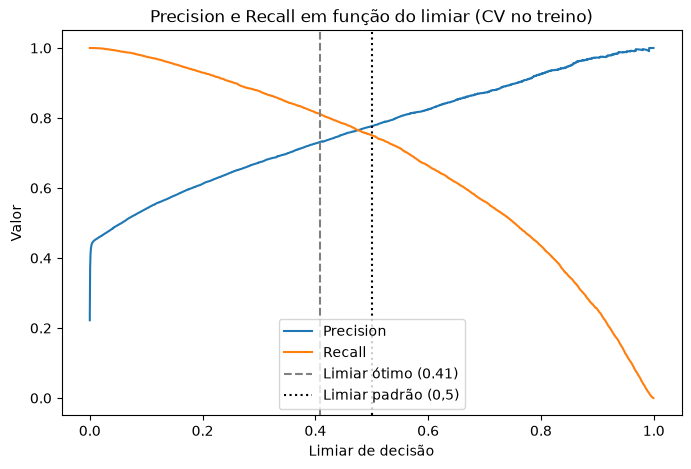

In [229]:
# Gráfico de Precision e Recall em função do limiar (CV no treino)
plt.figure(figsize=(8, 5))
plt.plot(lim, prec[:-1], label='Precision')
plt.plot(lim, rec[:-1], label='Recall')
plt.axvline(limiar_otimo, color='gray', linestyle='--', label=f'Limiar ótimo ({limiar_otimo:.2f})')
plt.axvline(0.5, color='black', linestyle=':', label='Limiar padrão (0,5)')
plt.xlabel('Limiar de decisão'); plt.ylabel('Valor')
plt.title('Precision e Recall em função do limiar (CV no treino)')
plt.legend(); plt.show()

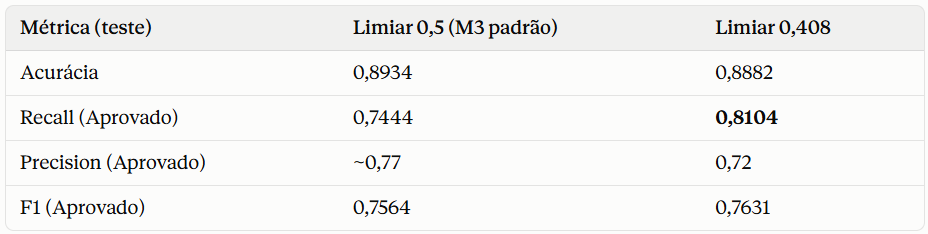

-   **Analisando o Resultado**

    -   O ganho é real, mas modesto. O recall sobe cerca de 6,6 p.p., o F1 sobe 0,007, e o preço é 5 p.p. de precision e 0,5 p.p. de acurácia. É exatamente o comportamento esperado: o limiar ótimo ficou perto de 0,4, e a curva do gráfico mostra que precision e recall se cruzam em torno de 0,45 a 0,5, com a região plana em torno do máximo do F1. Ou seja, o F1 varia pouco entre 0,4 e 0,5, e a escolha é mais de preferência de negócio do que de ganho estatístico.

    -   O limiar foi definido no treino (via CV) e o teste foi usado uma só vez, sem vazamento.

    -   Qual limiar adotar?
        -   A)  0,5 (padrão): mais precision (menos aprovações indevidas), menos recall. Defensável se o falso positivo é o erro mais caro.
        -   b)  0,408: captura mais aprovados reais (81%), com mais falsos positivos. Defensável se o objetivo é não perder clientes bons.

    -   Como o F1 é praticamente igual, escolha pelo critério de negócio mais conservador justificativa a opção pelo **modelo com limiar de 0,5**.

    -   O limiar de decisão foi otimizado por validação cruzada no conjunto de treino, buscando maximizar o F1 da classe aprovado, resultando em 0,408. No conjunto de teste, essa escolha elevou o recall de 0,744 para 0,810 e o F1 de 0,756 para 0,763, ao custo de redução da precision (de 0,77 para 0,72) e da acurácia (de 0,893 para 0,888). Como a curva de F1 é praticamente plana entre 0,4 e 0,5, a escolha do corte deve considerar o custo relativo de falsos positivos e falsos negativos no contexto de negócio.

### 5.8.3.  Tabela consolidada, matriz de confusão, ROC e coeficientes

In [230]:
# Gerando a tabela consolidade (teste)
def linha(n_vars, y_p, y_pr=None):
    return {
        'Nº variáveis': n_vars,
        'Acurácia': accuracy_score(y_test, y_p),
        'ROC-AUC': roc_auc_score(y_test, y_pr) if y_pr is not None else 0.5,
        'Precision (Aprovado)': precision_score(y_test, y_p, zero_division=0),
        'Recall (Aprovado)': recall_score(y_test, y_p),
        'F1 (Aprovado)': f1_score(y_test, y_p, zero_division=0),
    }

tabela_final = pd.DataFrame({
    'Baseline (burro)':        linha(0, y_pred_dummy),
    'M1 (todas)':              linha(X_train_s.shape[1], y_pred, y_proba),
    'M2 (3 variáveis)':        linha(3, y_pred_M2, y_proba_M2),
    'M3 (corte 0,5)':          linha(len(vars_M3), y_pred_M3, y_proba_M3),
    f'M3 (corte {limiar_otimo:.2f})': linha(len(vars_M3), y_pred_lim, proba_teste),
}).T
tabela_final.round(4)

,Nº variáveis,Acurácia,ROC-AUC,Precision (Aprovado),Recall (Aprovado),F1 (Aprovado)
Baseline (burro),0.0,0.7778,0.5000,0.0000,0.0000,0.0000
M1 (todas),21.0,0.8940,0.9522,0.7707,0.7448,0.7575
M2 (3 variáveis),3.0,0.8767,0.9340,0.7353,0.6956,0.7149
"M3 (corte 0,5)",13.0,0.8934,0.9522,0.7687,0.7444,0.7564
M3 (corte 0.41),13.0,0.8882,0.9522,0.7210,0.8104,0.7631


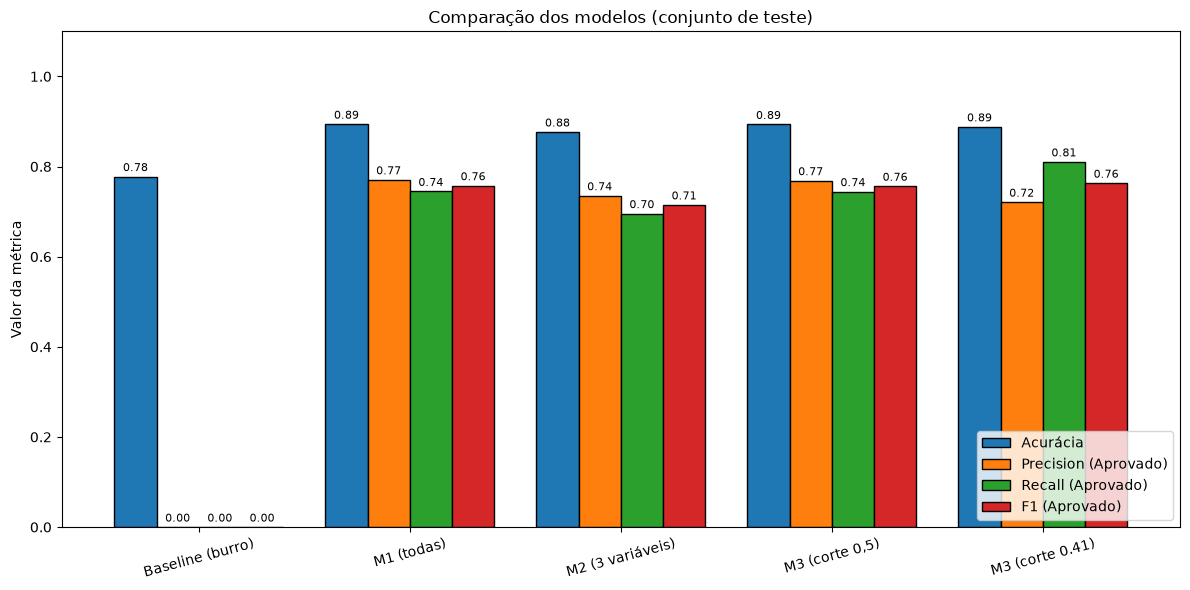

In [231]:
# Gráfico comparativo das métricas
met = tabela_final[['Acurácia', 'Precision (Aprovado)', 'Recall (Aprovado)', 'F1 (Aprovado)']]
ax = met.plot(kind='bar', figsize=(12, 6), width=0.8, edgecolor='black')
for c in ax.containers:
    ax.bar_label(c, fmt='%.2f', padding=2, fontsize=8)
plt.title('Comparação dos modelos (conjunto de teste)')
plt.ylabel('Valor da métrica'); plt.ylim(0, 1.1)
plt.xticks(rotation=15); plt.legend(loc='lower right')
plt.tight_layout(); plt.show()

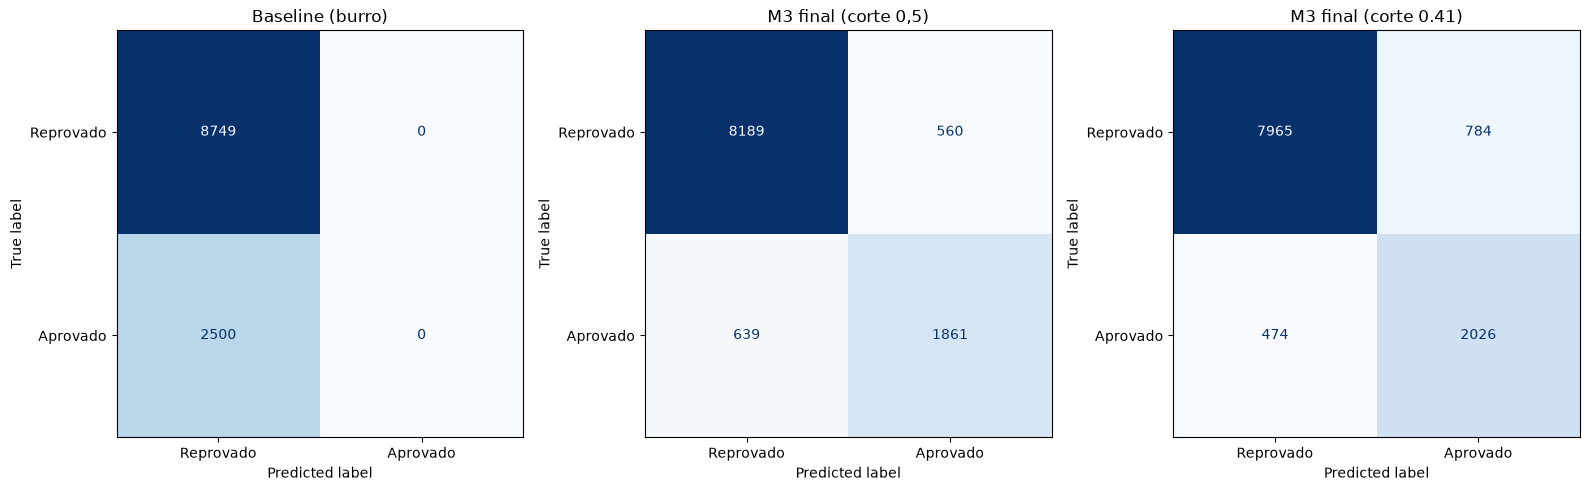

In [232]:
# Matrizes de confusão: baseline × M3 final
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (p, t) in zip(axes, [(y_pred_dummy, 'Baseline (burro)'),
                             (y_pred_M3, 'M3 final (corte 0,5)'),
                             (y_pred_lim, f'M3 final (corte {limiar_otimo:.2f})')]):
    ConfusionMatrixDisplay.from_predictions(
        y_test, p, display_labels=['Reprovado', 'Aprovado'],
        cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(t); ax.grid(False)
plt.tight_layout(); plt.show()

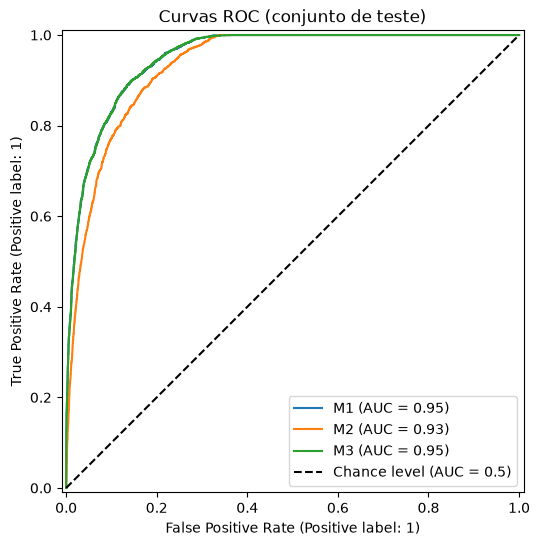

In [233]:
# Curva ROC: M1, M2 e M3
fig, ax = plt.subplots(figsize=(7, 6))
RocCurveDisplay.from_predictions(y_test, y_proba, name='M1', ax=ax)
RocCurveDisplay.from_predictions(y_test, y_proba_M2, name='M2', ax=ax)
RocCurveDisplay.from_predictions(y_test, y_proba_M3, name='M3', ax=ax,
                                 plot_chance_level=True)
plt.title('Curvas ROC (conjunto de teste)')
plt.show()

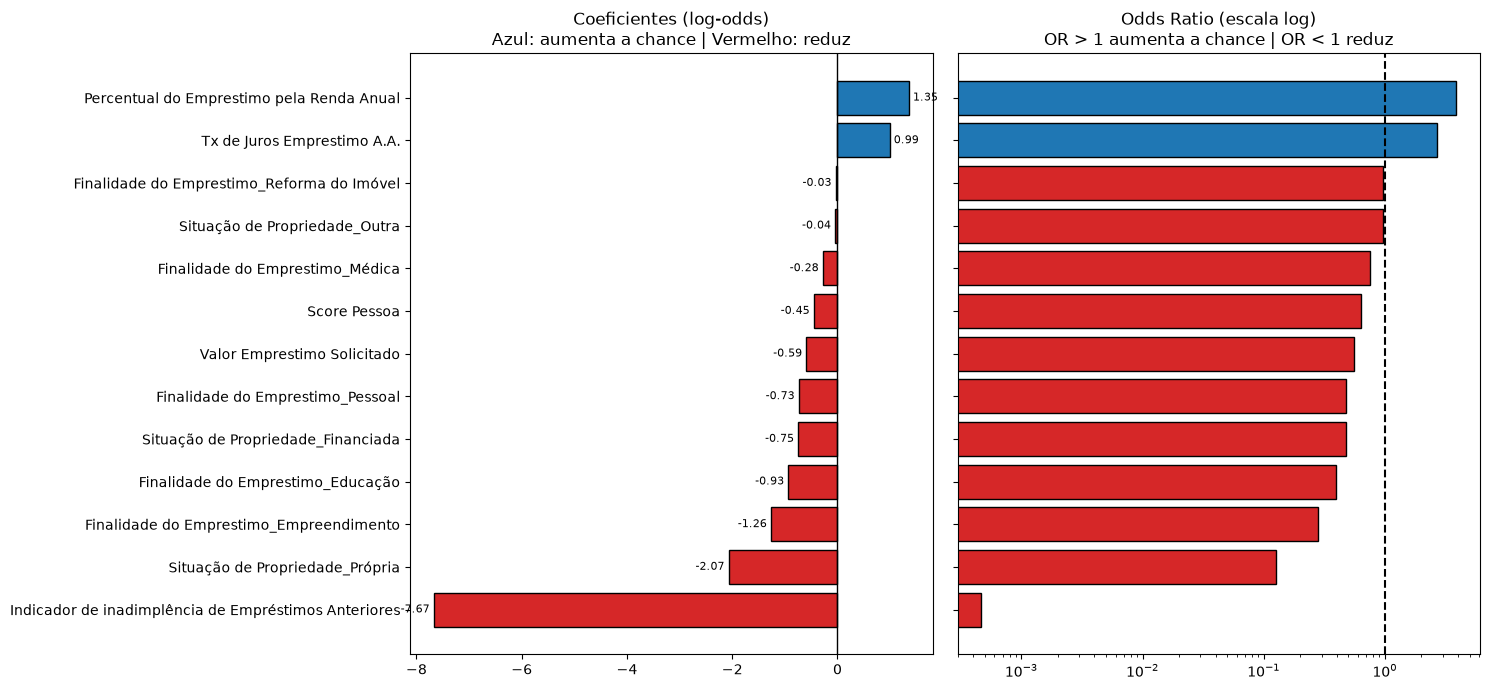

In [234]:
# Coeficientes e odds ratio do M3
coef3 = pd.DataFrame({
    'variavel': vars_M3,
    'coeficiente': modelo_M3.coef_[0],
    'odds_ratio': np.exp(modelo_M3.coef_[0])
}).sort_values('coeficiente')

fig, axes = plt.subplots(1, 2, figsize=(15, 7))

cores = ['#d62728' if v < 0 else '#1f77b4' for v in coef3['coeficiente']]
b = axes[0].barh(coef3['variavel'], coef3['coeficiente'], color=cores, edgecolor='black')
axes[0].bar_label(b, fmt='%.2f', padding=3, fontsize=8)
axes[0].axvline(0, color='black', linewidth=1)
axes[0].set_title('Coeficientes (log-odds)\nAzul: aumenta a chance | Vermelho: reduz')

axes[1].barh(coef3['variavel'], coef3['odds_ratio'], color=cores, edgecolor='black')
axes[1].set_xscale('log')
axes[1].axvline(1, color='black', linestyle='--')
axes[1].set_yticklabels([])
axes[1].set_title('Odds Ratio (escala log)\nOR > 1 aumenta a chance | OR < 1 reduz')

plt.tight_layout(); plt.show()

-   **MODELO VENCEDOR M3(Corte em 05)**

|Matriz (teste)	|Falsos positivos	|Falsos negativos	|Precision	|Recall	|F1|
|---|---|---|---|---|---|
|M3 corte 0,5|	560|	639|	0,77|	0,74|	0,76|
|M3 corte 0,41|	784|	474|	0,72|	0,81|	0,76|  

-   **Justificativas**

1.  M3 empata com o M1 e supera o M2. As curvas ROC de M1 e M3 estão sobrepostas (AUC 0,95), enquanto o M2 fica abaixo (0,93). O M3     entrega o mesmo desempenho com 13 variáveis em vez de 21, então vence pela parcimônia.      

2.  O alvo desta base é o status de aprovação ou reprovação. Assim, um falso positivo significa que o modelo prevê aprovação para um registro que consta como reprovado; isso não demonstra que o caso se tornará inadimplente. O conjunto não contém o resultado de pagamento futuro necessário para medir esse custo financeiro.
    Falso negativo: o modelo prevê reprovado para um registro que consta como aprovado.
    Falso positivo: o modelo prevê aprovação para um registro que consta como reprovado.
            
3.  Passar de 0,5 para 0,41 faz o modelo identificar 165 registros aprovados a mais (falsos negativos: 639 → 474), mas aumenta em 224 os registros rejeitados que ele classifica como aprovados (falsos positivos: 560 → 784). O F1 permanece próximo (0,76 nos dois cortes). Essa comparação mostra uma troca entre erros de classificação, não uma estimativa de perdas financeiras.           

4.  O corte 0,5 é uma referência padrão, mas não está demonstrado que minimize o custo do negócio. A escolha operacional deve considerar os impactos reais de cada erro e ser validada com dados adequados.

5.  O M3 (13 variáveis, corte 0,5) apresentou desempenho praticamente igual ao M1 (AUC 0,95; acurácia 0,893) com menos variáveis e superou o M2 (AUC 0,93). No corte 0,5, a precisão é 0,77 e o F1, 0,76; no corte 0,41, o recall aumenta para 0,81, mas também há mais registros rejeitados classificados como aprovados. 

6.  O corte 0,5 fica como referência para comparação, não como decisão comprovadamente mais segura: sem dados de inadimplência futura e sem custos definidos para cada erro, não é possível priorizar financeiramente um dos cortes. O M3 supera o baseline nas métricas que medem a identificação dos aprovados por por isso se mostrou uma opção mais conservadora com informações que possuimos até esse momento.

# 6.    Resultado Executivo do Trabalho

## 6.1. Objetivo e principais resultados

O trabalho analisou **45.000 registros** para classificar o status do empréstimo registrado na base. Segundo os metadados do projeto, 0 significa reprovado e 1 significa aprovado. A distribuição é desigual: **35.000 reprovado (77,8%)** e **10.000 aprovados (22,2%)**. Por isso, a acurácia sozinha pode enganar: um modelo que sempre previsse rejeição acertaria 77,8% dos casos, mas não encontraria nenhum aprovado.

O **M3** foi escolhido por manter resultados próximos aos do modelo completo usando menos variáveis. A comparação abaixo foi feita no conjunto de teste (11.249 registros):

| Modelo | Variáveis | Acurácia | ROC-AUC | Precisão dos aprovados | Recuperação dos aprovados | F1 dos aprovados |
|---|---:|---:|---:|---:|---:|---:|
| Baseline: sempre rejeita | 0 | 77,78% | 0,5000 | 0% | 0% | 0% |
| M1: modelo completo | 21 | 89,40% | 0,9522 | 77,07% | 74,48% | 75,75% |
| M2: modelo reduzido | 3 | 87,67% | 0,9340 | 73,53% | 69,56% | 71,49% |
| **M3: modelo escolhido** | **13** | **89,34%** | **0,9522** | **76,87%** | **74,44%** | **75,64%** |

Em linguagem simples, o M3 classificou corretamente cerca de **89 de cada 100 registros**. Sua ROC-AUC de 0,9522 indica boa capacidade de ordenar um aprovado acima de um rejeitado em comparações entre pares; não significa que o modelo acerta 95% dos casos. Entre os casos que classificou como aprovados, cerca de 77% eram aprovados na base (precisão); encontrou cerca de 74% de todos os aprovados reais (recuperação/recall).

## 6.2. Por que o M3 se destaca

- **Quase empata com o M1:** reduz de 21 para 13 variáveis (oito a menos, cerca de 38% de redução). A acurácia cai apenas 0,06 ponto percentual, a ROC-AUC permanece igual nos valores arredondados e o F1 cai 0,11 ponto percentual. Isso favorece um modelo mais simples sem perda relevante observada nesta avaliação.
- **Supera o M2:** as três variáveis do M2 não capturam tanta informação: sua acurácia é 1,67 ponto percentual menor que a do M3 e seu F1 é 4,15 pontos menor. As informações adicionais do M3 parecem contribuir para equilibrar a classificação.
- **Tem sinais de estabilidade dentro desta base:** na validação cruzada estratificada em cinco partes, a acurácia média foi 89,66% (desvio-padrão de 0,21 ponto percentual), a ROC-AUC 0,9547 (0,0009), a recuperação dos aprovados 75,05% (0,55 ponto) e o F1 76,34% (0,48 ponto). A variação pequena entre as partes é favorável, mas não garante o mesmo resultado em outros períodos ou populações.
- **Usa um conjunto de variáveis mais manejável:** inadimplência anterior, percentual do empréstimo em relação à renda, taxa de juros, valor solicitado, score, situação de propriedade e finalidade do empréstimo. A seleção considerou a análise estatística do modelo completo e a sobreposição entre variáveis. Uma associação estatística ajuda a identificar padrões, mas não prova causa e efeito.

## 6.3. Limite de decisão e tipos de erro

No corte de 0,5, o M3 classificou incorretamente **560 registros reprovado como aprovados** e **639 registros aprovados como reprovado**. Ao reduzir o corte para aproximadamente 0,41, passou a classificar incorretamente 784 reprovado como aprovados e 474 aprovados como reprovado. Ou seja, encontrou 165 aprovados a mais, mas também produziu 224 classificações incorretas a mais de reprovado como aprovados. Nesse corte, a recuperação sobe de 74,44% para 81,04%, a precisão cai de 76,87% para 72,10% e o F1 muda pouco (75,64% para 76,31%).

Esse é um equilíbrio entre dois tipos de erro, e o corte adequado depende do impacto real de cada um. **Importante:** a variável-alvo analisada é o status de aprovação/reprovação informado na base. Portanto, esses resultados não dizem se uma pessoa aprovada pagará o empréstimo ou ficará inadimplente. Não é possível concluir, apenas com estas métricas, que classificar um rejeitado como aprovado causará perda financeira. O corte 0,5 pode ser uma referência inicial, mas sua escolha operacional exige definir os custos dos erros e confirmar a finalidade do modelo.

## 6.4. Limitações e recomendações

1. **Confirmar o significado do alvo.** A coluna original chama-se `loan_status` ou Status da Aprovação do Empréstimo, enquanto os metadados a descrevem como aprovação (1) ou reprovado (0). Essa definição deve ser confirmada com a equipe de negócio. Se o objetivo for prever inadimplência futura, é necessário usar um resultado que represente pagamento ou atraso após a concessão; o M3 atual não responde a essa pergunta.
2. **Investigar o padrão de inadimplência anterior.** Na base, todos os registros marcados com inadimplência anterior (Yes) pertencem à classe rejeitada; entre os marcados No, 45,16% pertencem à classe aprovada. Esse padrão é muito forte e pode refletir uma regra já embutida na geração ou decisão dos dados. Verifique a origem e se ele se repete em dados reais e recentes; como o teste e a validação cruzada vêm da mesma base, ambos podem reproduzir o mesmo padrão.
3. **Validar em dados novos.** A validação cruzada e o teste demonstram consistência dentro da amostra analisada, mas não comprovam desempenho futuro, em outra região ou em outros perfis de clientes. É recomendável uma avaliação temporal e externa antes de qualquer uso operacional.
4. **Avaliar equidade e supervisão humana.** Antes de automatizar decisões, examine os erros por grupos relevantes e verifique se variáveis como situação de propriedade ou finalidade funcionam como representantes indiretos de características sensíveis. Mantenha monitoramento, revisão humana e possibilidade de contestação.
5. **Interpretar significância com cuidado.** Valores de p pequenos indicam associação sob as hipóteses estatísticas do modelo, não causalidade nem garantia de efeito. Em uma base grande, diferenças pequenas também podem ser estatisticamente significativas.

## 6.5. Conclusão

**O M3 é a alternativa mais equilibrada entre as avaliadas para reproduzir o status histórico desta base:** mantém desempenho praticamente igual ao M1 com menos variáveis e supera o M2 mais enxuto. A validação cruzada reforça a consistência dentro dos dados disponíveis. Ainda assim, deve ser tratado como apoio experimental, não como medida de risco de inadimplência nem como decisor automático de crédito, até que o significado do alvo, o padrão de inadimplência anterior, os custos dos erros e o desempenho em dados novos sejam confirmados.